### CÂU 1. PHÁT HIỆN LỖI SAI VÀ CHỈNH SỬA BIỂU ĐỒ

BƯỚC 1: Lỗi của code (chạy không đúng ý)

ggdraw(ggplot(...)) + scale_fill_manual(...) + labs(...) + theme(...): ggdraw() bọc biểu đồ vào một khung vẽ bên ngoài. Vì vậy scale_fill_manual, labs và theme được thêm vào khung ngoài chứ không tác động lên biểu đồ bên trong. Kết quả là màu, tiêu đề và theme không áp dụng như mong muốn.



size = 2 trong geom_bar và element_line(size = ...) đã bị thay bằng linewidth từ ggplot2 3.4 trở đi, nên có thể báo warning.
draw_text("bad") và draw_line(...) chỉ là phần trang trí đánh dấu “bad”, không có ý nghĩa dữ liệu.

BƯỚC 2: Lỗi trong biểu đồ

* Nhãn legend sai: biến cyl của mpg chỉ có giá trị 4, 5, 6, 8 chứ không có 3 và 7. Code gán nhãn “3, 5, 7, 8” là sai dữ liệu.
* Tên trục x sai: “Gear Types” không đúng. drv là loại dẫn động (4 = 4 bánh, f = cầu trước, r = cầu sau), không phải số cấp (gears).
* Tiêu đề sai và lẫn ngôn ngữ: “Số lượng of Gears vs Cylinders” trộn Việt và Anh. Nội dung cũng sai vì biểu đồ nói về loại dẫn động chứ không phải Gears.
* Trục y: “Count” cần đổi sang tiếng Việt cho đồng nhất: “Số lượng xe”.
Nhãn trục x: 4, f, r khó hiểu, nên đổi thành tên đầy đủ.
* Màu sắc rối mắt:
Viền vàng dày (size = 2) làm nhiễu các cột.
Tên trục x đỏ, trục y xanh lá không có ý nghĩa.
Lưới đỏ.
Bộ màu blue, red, green, purple có độ tương phản kém.
Thang đo / kích thước: angle = 90 trên tên trục y là thừa vì đó là mặc định. Chữ “bad” và đường kẻ đỏ làm sai lệch thông tin biểu đồ.



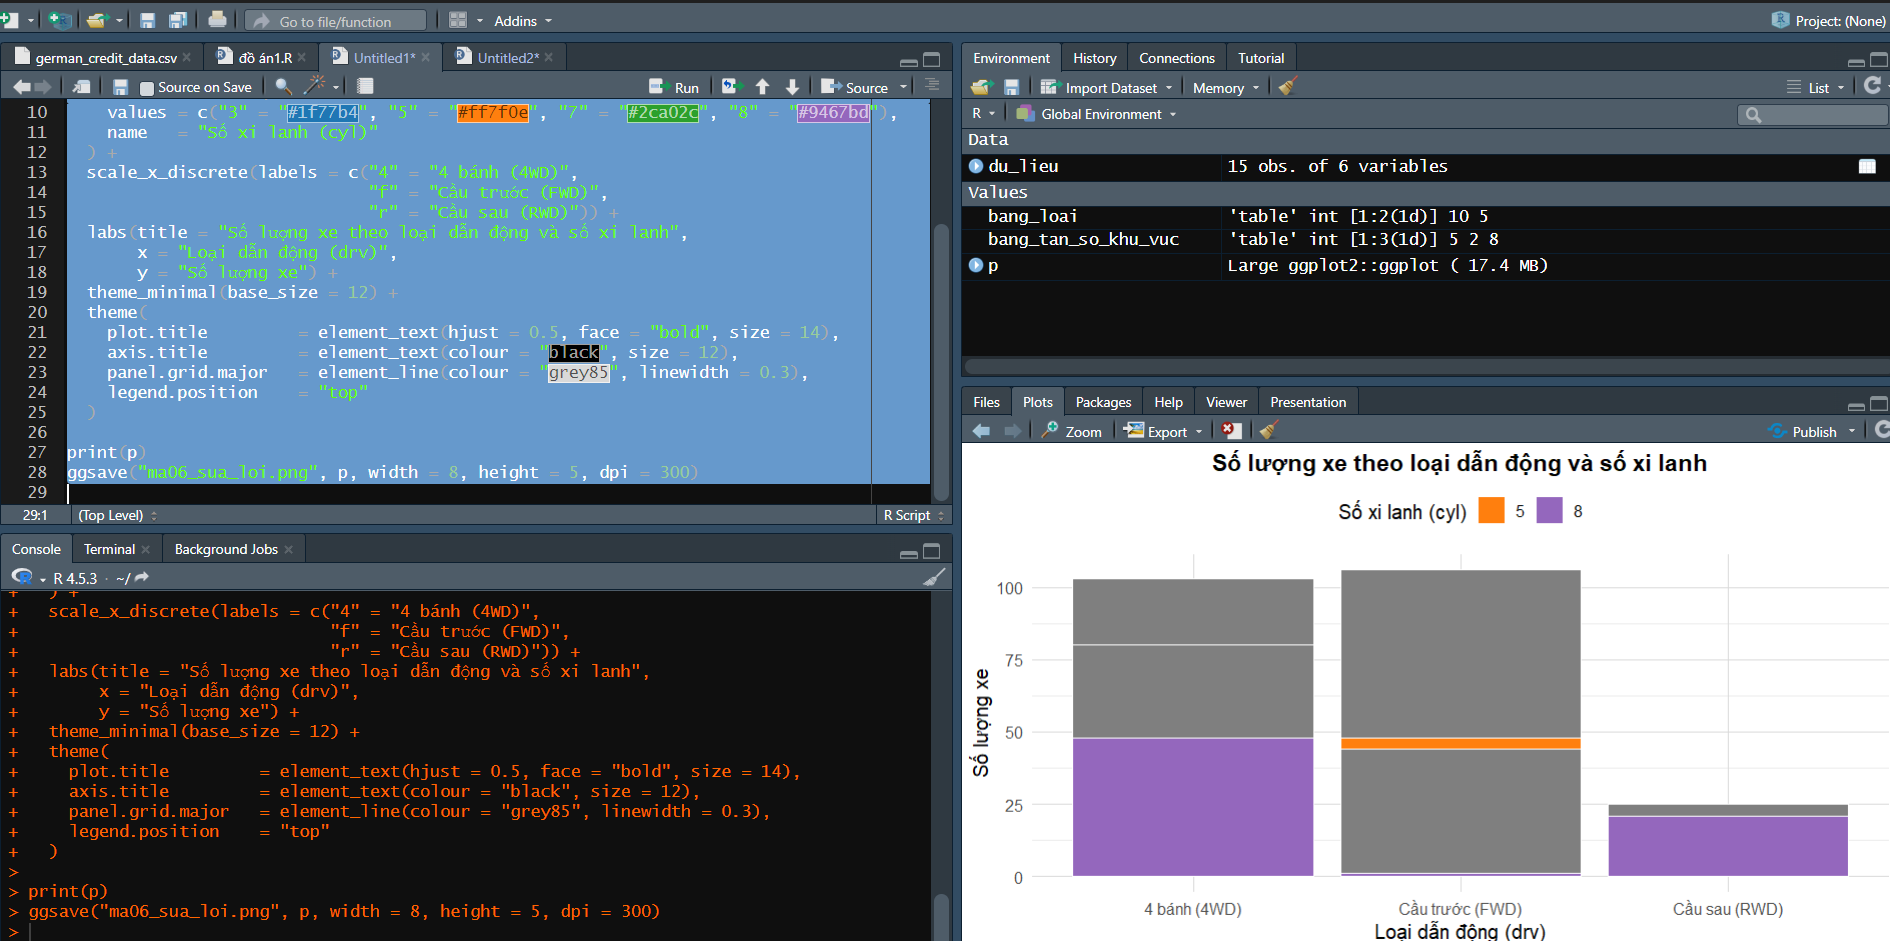

BƯỚC 3: Chỉnh sửa

* Bỏ ggdraw, draw_text, draw_line và đưa mọi thứ về một biểu đồ ggplot duy nhất.
Sửa nhãn cyl thành 4, 5, 6, 8 bằng cách đặt tên giá trị theo màu.
* Đổi tiêu đề và tên trục sang tiếng Việt: “Số lượng xe theo loại dẫn động và số xi lanh”, “Loại dẫn động (drv)”, “Số lượng xe”.
Đổi nhãn trục x thành “4 bánh (4WD)”, “Cầu trước (FWD)”, “Cầu sau (RWD)”.
* Dùng viền trắng mảnh, bộ màu dễ phân biệt, chữ trục màu đen, lưới xám nhạt và theme_minimal.
Giữ cột xếp chồng (stack) vì đang so sánh số lượng theo nhóm, và để chú thích ở phía trên.

In [ ]:
# MÃ 06 - ĐÃ CHỈNH SỬA
library(ggplot2)

# mpg có sẵn trong ggplot2; cyl chỉ nhận giá trị 4, 5, 6, 8
p <- ggplot(mpg, aes(x = factor(drv), fill = factor(cyl))) +
  geom_bar(position = "stack", colour = "white", linewidth = 0.4) +
  scale_fill_manual(
    values = c("4" = "#1f77b4", "5" = "#ff7f0e", "6" = "#2ca02c", "8" = "#9467bd"),
    name   = "Số xi lanh (cyl)"
  ) +
  scale_x_discrete(labels = c("4" = "4 bánh (4WD)",
                              "f" = "Cầu trước (FWD)",
                              "r" = "Cầu sau (RWD)")) +
  labs(title = "Số lượng xe theo loại dẫn động và số xi lanh",
       x = "Loại dẫn động (drv)",
       y = "Số lượng xe") +
  theme_minimal(base_size = 12) +
  theme(
    plot.title         = element_text(hjust = 0.5, face = "bold", size = 14),
    axis.title         = element_text(colour = "black", size = 12),
    panel.grid.major   = element_line(colour = "grey85", linewidth = 0.3),
    legend.position    = "top"
  )

print(p)
ggsave("ma06_sua_loi.png", p, width = 8, height = 5, dpi = 300)

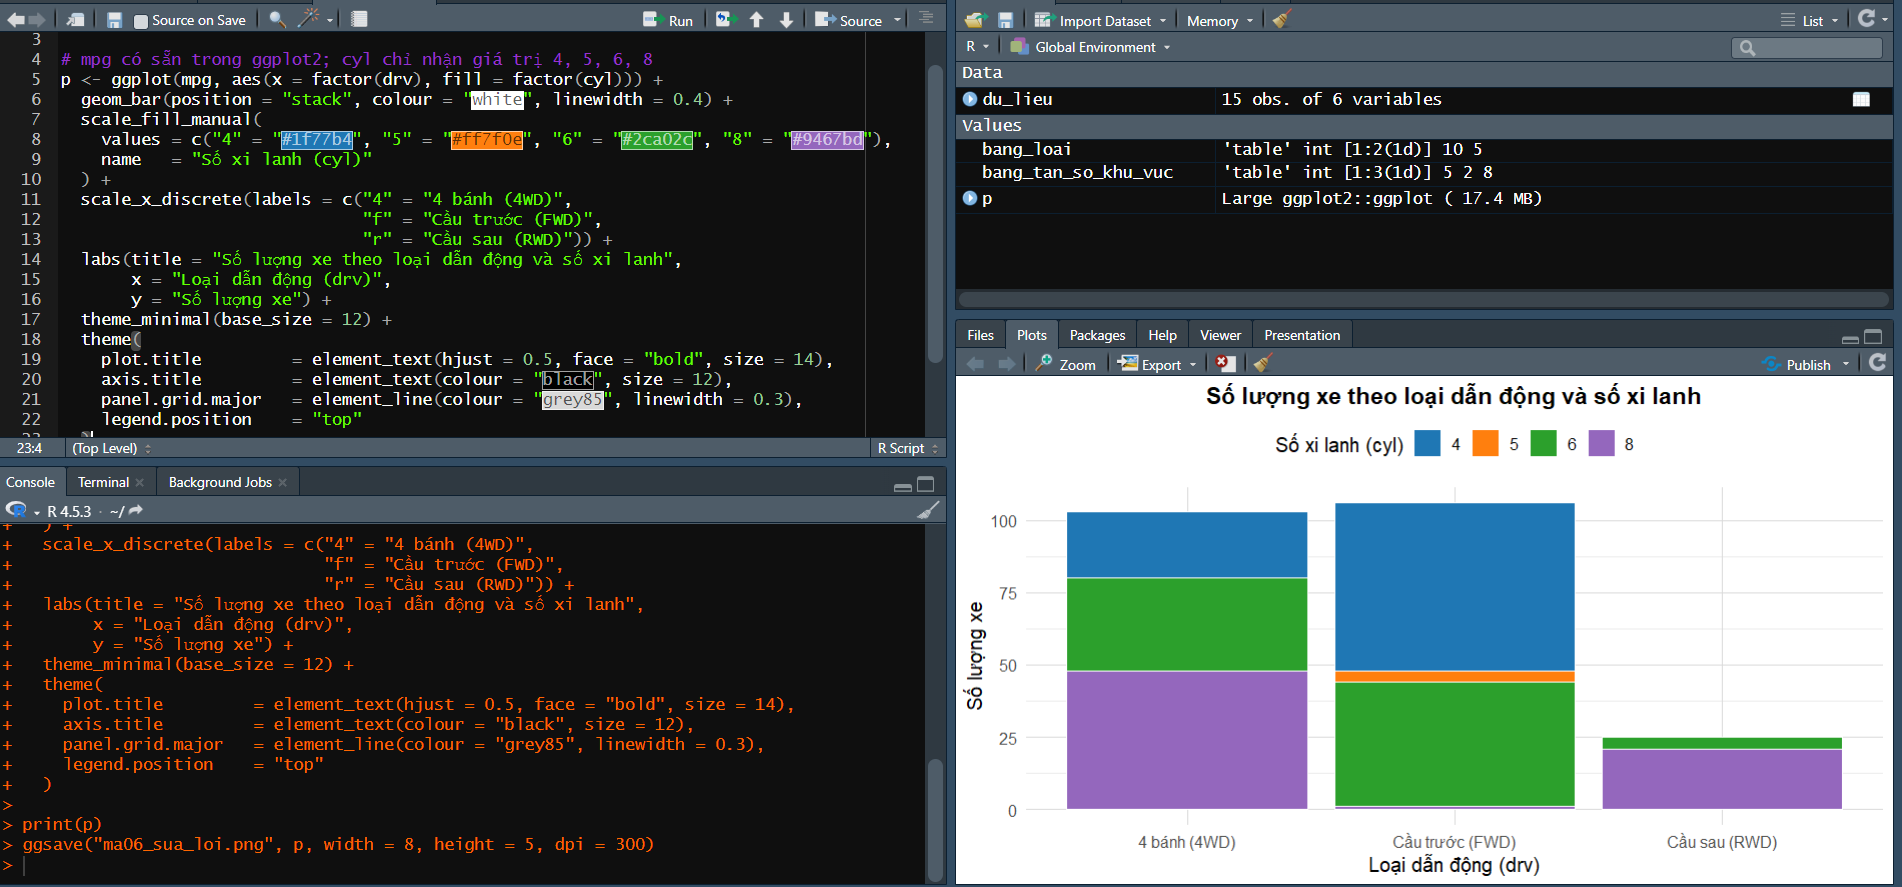

### CÂU 2. DỰA VÀO BỘ DỮ LIỆU DƯỚI ĐÂY HÃY
- CHO BIẾT THÔNG TIN TỔNG QUAN VỀ BỘ DỮ LIỆU
- THỰC HIỆN LÀM SẠCH DỮ LIỆU THEO QUY TRÌNH CƠ BẢN.
-SỬ DỰNG CÁC LOẠI BIỂU ĐỒ TỪ MỤC 1.6 ĐẾN 1.10 TRONG TÀI LIỆU HỌC TẬP, ĐỂ THĂM DÒ_KHAI PHÁ BỘ DỮ LIỆU NÀY.


MÃ ĐỀ 06
Giá vé máy bay **(Airfare Price Prediction**)
Mô tả: Chứa thông tin về hãng hàng không, ngày khởi hành, sân bay đi/đến, thời gian bay, số điểm dừng và giá vé.
* Link tải: https://www.kaggle.com/datasets/shubhambathwal/flight-price-prediction-dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os, re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats


In [ ]:


# Đọc dữ liệu từ Google Drive
df = pd.read_csv('/content/drive/MyDrive/business.csv')

display(df.head())

,date,airline,ch_code,num_code,dep_time,from,time_taken,stop,arr_time,to,price
0,11-02-2022,Air India,AI,868,18:00,Delhi,02h 00m,non-stop,20:00,Mumbai,"25,612"
1,11-02-2022,Air India,AI,624,19:00,Delhi,02h 15m,non-stop,21:15,Mumbai,"25,612"
2,11-02-2022,Air India,AI,531,20:00,Delhi,24h 45m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,20:45,Mumbai,"42,220"
3,11-02-2022,Air India,AI,839,21:25,Delhi,26h 30m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,23:55,Mumbai,"44,450"
4,11-02-2022,Air India,AI,544,17:15,Delhi,06h 40m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,23:55,Mumbai,"46,690"


 ## 1. Thông tin tổng quan về bộ dữ liệu

**Cấu trúc notebook**

| Phần | Nội dung |
|---|---|
| 1 | Thông tin tổng quan về bộ dữ liệu |
| 2 | Làm sạch dữ liệu theo quy trình cơ bản |
| 3 | **Mục 1.6** – Trực quan hóa số lượng (bar, grouped/stacked, dot plot, heatmap) |
| 4 | **Mục 1.7 – 1.8** – Trực quan hóa phân phối (histogram, density, ECDF, log, Q-Q) |
| 5 | **Mục 1.9** – Nhiều phân phối cùng lúc (strip, box, violin, ridgeline) |
| 6 | **Mục 1.10** – Trực quan hóa tỷ lệ (pie, side-by-side, stacked, small multiples) |
| 7 | Tổng hợp phát hiện & kết luận |


Quan sát dữ liệu **thô (raw)** trước khi làm sạch: kích thước, kiểu dữ liệu, giá trị thiếu, trùng lặp, thống kê mô tả.

In [ ]:
print('Số dòng (quan sát):', f'{df.shape[0]:,}')
print('Số cột (biến)     :', df.shape[1])
print('Bộ nhớ sử dụng    :', f'{df.memory_usage(deep=True).sum() / 1024**2:,.1f} MB')
df.head(8)

Số dòng (quan sát): 93,487
Số cột (biến)     : 11
Bộ nhớ sử dụng    : 52.1 MB


,date,airline,ch_code,num_code,dep_time,from,time_taken,stop,arr_time,to,price
0,11-02-2022,Air India,AI,868,18:00,Delhi,02h 00m,non-stop,20:00,Mumbai,"25,612"
1,11-02-2022,Air India,AI,624,19:00,Delhi,02h 15m,non-stop,21:15,Mumbai,"25,612"
2,11-02-2022,Air India,AI,531,20:00,Delhi,24h 45m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,20:45,Mumbai,"42,220"
3,11-02-2022,Air India,AI,839,21:25,Delhi,26h 30m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,23:55,Mumbai,"44,450"
4,11-02-2022,Air India,AI,544,17:15,Delhi,06h 40m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,23:55,Mumbai,"46,690"
5,11-02-2022,Vistara,UK,985,19:50,Delhi,02h 10m,non-stop,22:00,Mumbai,"50,264"
6,11-02-2022,Air India,AI,479,21:15,Delhi,17h 45m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,15:00,Mumbai,"50,669"
7,11-02-2022,Air India,AI,473,18:40,Delhi,22h 45m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,17:25,Mumbai,"51,059"


In [ ]:
# Bảng mô tả cấu trúc: kiểu dữ liệu, số giá trị thiếu, số giá trị duy nhất, ví dụ
info = pd.DataFrame({
    'Kiểu dữ liệu': df.dtypes.astype(str),
    'Số thiếu': df.isna().sum(),
    '% thiếu': df.isna().mean() * 100,
    'Số giá trị duy nhất': df.nunique(),
    'Ví dụ': [repr(df[c].dropna().iloc[0]) if df[c].notna().any() else '' for c in df.columns],
})
info

,Kiểu dữ liệu,Số thiếu,% thiếu,Số giá trị duy nhất,Ví dụ
date,object,0,0.0,49,'11-02-2022'
airline,object,0,0.0,2,'Air India'
ch_code,object,0,0.0,2,'AI'
num_code,int64,0,0.0,264,np.int64(868)
dep_time,object,0,0.0,166,'18:00'
from,object,0,0.0,6,'Delhi'
time_taken,object,0,0.0,373,'02h 00m'
stop,object,0,0.0,25,'non-stop '
arr_time,object,0,0.0,176,'20:00'
to,object,0,0.0,6,'Mumbai'


In [ ]:
print('Số dòng trùng lặp hoàn toàn:', f'{df.duplicated().sum():,}',
      f'({df.duplicated().mean() * 100:.2f}%)')
print()
print('Thống kê mô tả các biến số (dữ liệu thô):')
display(df.describe().T)
print('Thống kê mô tả các biến dạng chữ (dữ liệu thô):')
display(df.describe(include=['object', 'string']).T if df.select_dtypes(include=['object', 'string']).shape[1] else 'Không có')

Số dòng trùng lặp hoàn toàn: 0 (0.00%)

Thống kê mô tả các biến số (dữ liệu thô):


,count,mean,std,min,25%,50%,75%,max
num_code,93487.0,780.056147,147.616038,401.0,706.0,820.0,874.0,996.0


Thống kê mô tả các biến dạng chữ (dữ liệu thô):


,count,unique,top,freq
date,93487,49,07-03-2022,2062
airline,93487,2,Vistara,60589
ch_code,93487,2,UK,60589
dep_time,93487,166,07:00,3805
from,93487,6,Mumbai,19858
time_taken,93487,373,02h 10m,1161
stop,93487,25,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,81489
arr_time,93487,176,19:55,4192
to,93487,6,Mumbai,18991
price,93487,2358,"54,608",1445


**Mô tả ý nghĩa các biến** (tên cột có thể khác nhau tùy file `economy/business` hoặc `Clean_Dataset`):

| Ý nghĩa | File economy/business | File Clean_Dataset |
|---|---|---|
| Ngày khởi hành | `date` | *(không có – thay bằng `days_left`)* |
| Hãng hàng không | `airline` | `airline` |
| Mã chuyến bay | `ch_code` + `num_code` | `flight` |
| Sân bay/thành phố đi | `from` | `source_city` |
| Sân bay/thành phố đến | `to` | `destination_city` |
| Giờ khởi hành / đến | `dep_time`, `arr_time` | `departure_time`, `arrival_time` (đã chia nhóm) |
| Thời gian bay | `time_taken` (chuỗi *“02h 10m”*) | `duration` (số giờ) |
| Số điểm dừng | `stop` (chuỗi) | `stops` (zero / one / two_or_more) |
| Hạng ghế | *(theo file: economy / business)* | `class` |
| Số ngày đặt trước | `days_left` | `days_left` |
| **Giá vé (biến mục tiêu)** | `price` (chuỗi có dấu phẩy) | `price` |

In [ ]:
# Phân bố nhanh các biến phân loại chính của dữ liệu thô
for c in df.columns:
    if df[c].nunique() <= 12 and c.lower() not in ('unnamed: 0',):
        print(f'--- {c} ---')
        print(df[c].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip().value_counts().to_string())
        print()

--- airline ---
airline
Vistara      60589
Air India    32898

--- ch_code ---
ch_code
UK    60589
AI    32898

--- from ---
from
Mumbai       19858
Delhi        18316
Bangalore    16441
Kolkata      13473
Hyderabad    12870
Chennai      12529

--- to ---
to
Mumbai       18991
Delhi        16707
Bangalore    16198
Kolkata      14758
Hyderabad    13675
Chennai      13158



## 2. Làm sạch dữ liệu theo quy trình cơ bản

Quy trình thực hiện (mỗi bước đều in kết quả để kiểm chứng):

1. Sao chép dữ liệu thô, chuẩn hóa **tên cột** và **khoảng trắng** trong chuỗi
2. Ép **kiểu dữ liệu** đúng (giá vé, thời gian bay, ngày, số điểm dừng, nhóm giờ bay)
3. Xử lý **giá trị thiếu**
4. Xử lý **dòng trùng lặp**
5. Kiểm tra **tính hợp lý** (logic) của dữ liệu
6. Phát hiện **ngoại lệ (outlier)** bằng IQR – *đánh dấu, không xóa*
7. **Tạo biến mới** & đặt thứ tự cho biến phân loại
8. So sánh trước/sau và **lưu file đã làm sạch**

Bước 1 : Chuẩn hóa tên cột và chuỗi

In [ ]:
df = df.copy()
n_df = len(df)

# tên cột: chữ thường, bỏ khoảng trắng, bỏ cột chỉ số thừa (Unnamed: 0)
df.columns = df.columns.str.replace('\ufeff', '', regex=False).str.strip().str.lower().str.replace(r'\s+', '_', regex=True)
df = df.loc[:, ~df.columns.str.startswith('unnamed')]

# chuỗi: gộp ký tự trắng (\n, \t, nhiều dấu cách) và cắt hai đầu
for c in df.columns:
    if pd.api.types.is_string_dtype(df[c]) or pd.api.types.is_object_dtype(df[c]):
        df[c] = df[c].astype(object).where(df[c].isna(), df[c].astype(str).str.replace(r'\\[nt]', ' ', regex=True).str.replace(r'\s+', ' ', regex=True).str.strip())

print('Các cột sau chuẩn hóa:', list(df.columns))

Các cột sau chuẩn hóa: ['date', 'airline', 'ch_code', 'num_code', 'dep_time', 'from', 'time_taken', 'stop', 'arr_time', 'to', 'price']


Bước 2: Ép kiểu dữ liệu và thống nhất lược đồ cột

In [ ]:
SCHEMA = 'raw'
TIME_ORDER  = ['Early_Morning', 'Morning', 'Afternoon', 'Evening', 'Night', 'Late_Night']
STOPS_ORDER = ['zero', 'one', 'two_or_more']

def parse_duration(s):
    """'02h 10m' → 2.1666 (giờ)"""
    if pd.isna(s):
        return np.nan
    s = str(s)
    h = re.search(r'(\d+)\s*h', s)
    m = re.search(r'(\d+)\s*m', s)
    if not h and not m:
        return np.nan
    return (int(h.group(1)) if h else 0) + (int(m.group(1)) if m else 0) / 60

def parse_stops(s):
    """'non-stop' → zero ; '1-stop Via Mumbai' → one ; '2+-stop' → two_or_more"""
    if pd.isna(s):
        return np.nan
    s = str(s).lower()
    if 'non' in s:
        return 'zero'
    m = re.search(r'(\d+)\+?\s*-?\s*stop', s)
    if m:
        return 'one' if int(m.group(1)) == 1 else 'two_or_more'
    return np.nan

def extract_hour(series):
    """'18:05' hoặc '08:40 +1 day' → 18 / 8"""
    h = series.astype(str).str.extract(r'(\d{1,2}):(\d{2})')[0]
    return pd.to_numeric(h, errors='coerce')

def hour_to_bin(h):
    if pd.isna(h):
        return np.nan
    h = int(h)
    if 4 <= h < 8:   return 'Early_Morning'
    if 8 <= h < 12:  return 'Morning'
    if 12 <= h < 16: return 'Afternoon'
    if 16 <= h < 20: return 'Evening'
    if 20 <= h < 24: return 'Night'
    return 'Late_Night'

if SCHEMA == 'raw':
    df['price']    = pd.to_numeric(df['price'].astype(str).str.replace(',', '', regex=False), errors='coerce')
    df['duration'] = df['time_taken'].apply(parse_duration)
    df['stops']    = df['stop'].apply(parse_stops)
    df['date']     = pd.to_datetime(df['date'], dayfirst=True, errors='coerce')
    dep_h, arr_h   = extract_hour(df['dep_time']), extract_hour(df['arr_time'])
    df['dep_hour'] = dep_h
    df['departure_time'] = dep_h.apply(hour_to_bin)
    df['arrival_time']   = arr_h.apply(hour_to_bin)
    df['flight']   = df['ch_code'].astype(str) + '-' + df['num_code'].astype(str)
    df['class']    = 'Business'
    df = df.rename(columns={'from': 'source_city', 'to': 'destination_city'})
else:
    df['price']    = pd.to_numeric(df['price'], errors='coerce')
    df['duration'] = pd.to_numeric(df['duration'], errors='coerce')

df['class'] = df['class'].astype(str).str.strip().str.title()
for c in ['airline', 'source_city', 'destination_city']:
    df[c] = df[c].astype(str).str.strip()

core  = ['airline', 'flight', 'source_city', 'destination_city',
         'departure_time', 'arrival_time', 'stops', 'class', 'duration', 'price']
extra = [c for c in ['date', 'days_left', 'dep_hour'] if c in df.columns]
df = df[extra[:1] + core + extra[1:]] if 'date' in extra else df[core + extra]

print('Kiểu dữ liệu sau khi ép kiểu:')
print(df.dtypes.to_string())
display(df.head())

Kiểu dữ liệu sau khi ép kiểu:
date                datetime64[ns]
airline                     object
flight                      object
source_city                 object
destination_city            object
departure_time              object
arrival_time                object
stops                       object
class                       object
duration                   float64
price                        int64
dep_hour                     int64


,date,airline,flight,source_city,destination_city,departure_time,arrival_time,stops,class,duration,price,dep_hour
0,2022-02-11,Air India,AI-868,Delhi,Mumbai,Evening,Night,zero,Business,2.000000,25612,18
1,2022-02-11,Air India,AI-624,Delhi,Mumbai,Evening,Night,zero,Business,2.250000,25612,19
2,2022-02-11,Air India,AI-531,Delhi,Mumbai,Night,Night,one,Business,24.750000,42220,20
3,2022-02-11,Air India,AI-839,Delhi,Mumbai,Night,Night,one,Business,26.500000,44450,21
4,2022-02-11,Air India,AI-544,Delhi,Mumbai,Evening,Night,one,Business,6.666667,46690,17


Bước 3 : Giá trị thiếu

In [ ]:
miss = df.isna().sum()
print('Số giá trị thiếu theo cột:')
print(miss[miss > 0].to_string() if (miss > 0).any() else 'Không có giá trị thiếu.')

# Chiến lược:
#  - Thiếu biến mục tiêu (price) hoặc biến định danh chính → xóa dòng (không thể suy đoán)
#  - Thiếu duration → điền trung vị theo (tuyến bay, số điểm dừng), phần còn lại điền trung vị toàn bộ
n0 = len(df)
df = df.dropna(subset=['price', 'airline', 'source_city', 'destination_city', 'class'])
grp_med = df.groupby(['source_city', 'destination_city', 'stops'])['duration'].transform('median')
df['duration'] = df['duration'].fillna(grp_med).fillna(df['duration'].median())
df = df.dropna(subset=['departure_time', 'arrival_time', 'stops', 'duration'])
print(f'\nĐã xóa {n0 - len(df):,} dòng thiếu dữ liệu quan trọng.')

Số giá trị thiếu theo cột:
Không có giá trị thiếu.

Đã xóa 0 dòng thiếu dữ liệu quan trọng.


Bước 4: Dòng trùng lặp

In [ ]:
n_dup = df.duplicated().sum()
print(f'Số dòng trùng lặp hoàn toàn: {n_dup:,}')
df = df.drop_duplicates().reset_index(drop=True)
print(f'Còn lại {len(df):,} dòng sau khi loại trùng.')

Số dòng trùng lặp hoàn toàn: 0
Còn lại 93,487 dòng sau khi loại trùng.


Bước 5: Kiểm tra tính hợp lý (logic)

In [ ]:
checks = {
    'Giá vé ≤ 0':                      (df['price'] <= 0),
    'Thời gian bay ≤ 0':               (df['duration'] <= 0),
    'Thời gian bay > 48 giờ':          (df['duration'] > 48),
    'Điểm đi trùng điểm đến':          (df['source_city'] == df['destination_city']),
    'Số điểm dừng không hợp lệ':       (~df['stops'].isin(STOPS_ORDER)),
    'Hạng ghế không phải Business':     (df['class'] != 'Business'),
}
report = pd.Series({k: int(v.sum()) for k, v in checks.items()}, name='Số dòng vi phạm')
display(report.to_frame())

bad = np.zeros(len(df), dtype=bool)
for v in checks.values():
    bad |= v.values
df = df.loc[~bad].reset_index(drop=True)
print(f'Đã loại {bad.sum():,} dòng không hợp lý. Còn lại {len(df):,} dòng.')

print('Hạng ghế còn lại:', df['class'].unique().tolist())

,Số dòng vi phạm
Giá vé ≤ 0,0
Thời gian bay ≤ 0,0
Thời gian bay > 48 giờ,0
Điểm đi trùng điểm đến,0
Số điểm dừng không hợp lệ,0
Hạng ghế không phải Business,0


Đã loại 0 dòng không hợp lý. Còn lại 93,487 dòng.
Hạng ghế còn lại: ['Business']


Bước 6: Phát hiện ngoại lệ (IQR) - đánh dấu, không xóa

In [ ]:
def iqr_flag(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

df['price_outlier'] = iqr_flag(df['price'])

out_tab = pd.DataFrame({
    'Số dòng': [len(df)], 'Trung vị': [df['price'].median()],
    'Q1': [df['price'].quantile(.25)], 'Q3': [df['price'].quantile(.75)],
    'Số ngoại lệ': [int(df['price_outlier'].sum())],
    '% ngoại lệ': [df['price_outlier'].mean() * 100]}, index=['Business'])
display(out_tab)

print('''Quyết định: GIỮ LẠI các giá trị ngoại lệ vì đây là giá vé thật (chuyến bay đặt sát ngày, giờ cao điểm...),
không phải lỗi nhập liệu. Thay vào đó dùng thang log / biểu đồ không bị nhạy với ngoại lệ ở các phần sau.''')

,Số dòng,Trung vị,Q1,Q3,Số ngoại lệ,% ngoại lệ
Business,93487,53164.0,45185.0,60396.0,3650,3.904286


Quyết định: GIỮ LẠI các giá trị ngoại lệ vì đây là giá vé thật (chuyến bay đặt sát ngày, giờ cao điểm...),
không phải lỗi nhập liệu. Thay vào đó dùng thang log / biểu đồ không bị nhạy với ngoại lệ ở các phần sau.


Bước 7: Tạo biến mới và đặt biến thứ tự cho biến phân loại

In [ ]:
df['route']       = df['source_city'] + ' → ' + df['destination_city']
df['price_log10'] = np.log10(df['price'])
df['price_per_hour'] = df['price'] / df['duration']
df['stops_num']   = df['stops'].map({'zero': 0, 'one': 1, 'two_or_more': 2})

# Biến phân loại có thứ tự tự nhiên → giữ nguyên thứ tự (nguyên tắc slide 1.6.1)
df['departure_time'] = pd.Categorical(df['departure_time'], categories=TIME_ORDER, ordered=True)
df['arrival_time']   = pd.Categorical(df['arrival_time'],   categories=TIME_ORDER, ordered=True)
df['stops']          = pd.Categorical(df['stops'],          categories=STOPS_ORDER, ordered=True)
df['class']          = pd.Categorical(df['class'], categories=['Business'])

# Nhóm thời gian dùng cho biểu đồ ridgeline (mục 1.9)
if 'date' in df.columns and df['date'].notna().any() and 'days_left' not in df.columns:
    wk = df['date'].dt.to_period('W').dt.start_time
    TG_ORDER = wk.drop_duplicates().sort_values().dt.strftime('%d/%m').tolist()
    df['time_group'] = pd.Categorical(wk.dt.strftime('%d/%m'), categories=TG_ORDER, ordered=True)
    TG_LABEL = 'Tuần khởi hành (ngày đầu tuần, dd/mm)'
    df['dep_month']   = df['date'].dt.month
    df['dep_weekday'] = df['date'].dt.day_name()
elif 'days_left' in df.columns:
    bins   = [0, 7, 14, 21, 28, 35, 42, 100]
    TG_ORDER = ['1–7', '8–14', '15–21', '22–28', '29–35', '36–42', '43+']
    df['time_group'] = pd.cut(df['days_left'], bins=bins, labels=TG_ORDER)
    TG_LABEL = 'Số ngày đặt vé trước chuyến bay'
else:
    TG_ORDER = TIME_ORDER
    df['time_group'] = df['departure_time']
    TG_LABEL = 'Khung giờ khởi hành'

df.head()

,date,airline,flight,source_city,destination_city,departure_time,arrival_time,stops,class,duration,price,dep_hour,price_outlier,route,price_log10,price_per_hour,stops_num,time_group,dep_month,dep_weekday
0,2022-02-11,Air India,AI-868,Delhi,Mumbai,Evening,Night,zero,Business,2.000000,25612,18,False,Delhi → Mumbai,4.408443,12806.000000,0,07/02,2,Friday
1,2022-02-11,Air India,AI-624,Delhi,Mumbai,Evening,Night,zero,Business,2.250000,25612,19,False,Delhi → Mumbai,4.408443,11383.111111,0,07/02,2,Friday
2,2022-02-11,Air India,AI-531,Delhi,Mumbai,Night,Night,one,Business,24.750000,42220,20,False,Delhi → Mumbai,4.625518,1705.858586,1,07/02,2,Friday
3,2022-02-11,Air India,AI-839,Delhi,Mumbai,Night,Night,one,Business,26.500000,44450,21,False,Delhi → Mumbai,4.647872,1677.358491,1,07/02,2,Friday
4,2022-02-11,Air India,AI-544,Delhi,Mumbai,Evening,Night,one,Business,6.666667,46690,17,False,Delhi → Mumbai,4.669224,7003.500000,1,07/02,2,Friday


Bước 8: So sánh trc và sau lưu file

In [ ]:
summary = pd.DataFrame({
    'Trước làm sạch': [n_df, df.shape[1], int(df.isna().sum().sum()), int(df.duplicated().sum())],
    'Sau làm sạch':   [len(df), df.shape[1], int(df.isna().sum().sum()), int(df.duplicated().sum())],
}, index=['Số dòng', 'Số cột', 'Tổng ô thiếu', 'Dòng trùng'])
display(summary)

print('\nKiểu dữ liệu cuối cùng:')
print(df.dtypes.to_string())

df.to_csv('flight_price_cleaned.csv', index=False, encoding='utf-8-sig')
print('\nĐã lưu: flight_price_cleaned.csv')

,Trước làm sạch,Sau làm sạch
Số dòng,93487,93487
Số cột,20,20
Tổng ô thiếu,0,0
Dòng trùng,0,0



Kiểu dữ liệu cuối cùng:
date                datetime64[ns]
airline                     object
flight                      object
source_city                 object
destination_city            object
departure_time            category
arrival_time              category
stops                     category
class                     category
duration                   float64
price                        int64
dep_hour                     int64
price_outlier                 bool
route                       object
price_log10                float64
price_per_hour             float64
stops_num                    int64
time_group                category
dep_month                    int32
dep_weekday                 object

Đã lưu: flight_price_cleaned.csv


## Chuẩn bị dùng chung cho các biểu đồ
Toàn bộ dữ liệu giờ chỉ gồm hạng Business, nên các biểu đồ so sánh nhóm sẽ dùng **hãng bay** (Vistara, Air India), **thành phố đi**, **khung giờ**, **số điểm dừng**, **thời gian**. Tạo mẫu ngẫu nhiên cho những biểu đồ nặng (KDE, strip, violin).

In [ ]:
bus = df
bus_s = bus.sample(min(len(bus), 30000), random_state=42)

airlines = sorted(bus['airline'].unique())
AIR_COLORS = dict(zip(airlines, ['#56B4E9', '#D55E00', '#009E73', '#E69F00', '#CC79A7', '#0072B2']))
print(f'Business: {len(bus):,} dòng | Hãng: {airlines}')

PRICE_TICKS = (20000, 30000, 40000, 50000, 70000, 100000, 150000)

def log10_ticks(ax, axis='y', vals=(500, 1000, 2000, 5000, 10000, 20000, 50000, 100000, 200000)):
    lo, hi = (ax.get_ylim() if axis == 'y' else ax.get_xlim())
    t = [v for v in vals if lo <= np.log10(v) <= hi]
    labels = [f'{v:,}' for v in t]
    if axis == 'y':
        ax.set_yticks(np.log10(t)); ax.set_yticklabels(labels)
    else:
        ax.set_xticks(np.log10(t)); ax.set_xticklabels(labels)

Business: 93,487 dòng | Hãng: ['Air India', 'Vistara']


---
# 3. MỤC 1.6 – TRỰC QUAN HÓA SỐ LƯỢNG (Visualizing Amounts)
"Số lượng" = tập hợp các **danh mục** (thành phố, hãng, tuyến bay...) đi kèm **một giá trị định lượng** (số chuyến, giá trung vị...). Mục tiêu: so sánh độ lớn một cách trực quan và chính xác nhất.

## 3.1 Biểu đồ thanh (Bar chart) – 1 biến phân loại
**Quy tắc:** xoay ngang khi nhãn dài · sắp xếp theo độ lớn (biến không có thứ tự) · biến có **thứ tự tự nhiên** (khung giờ) thì **giữ nguyên thứ tự** · **trục bắt đầu từ 0**.

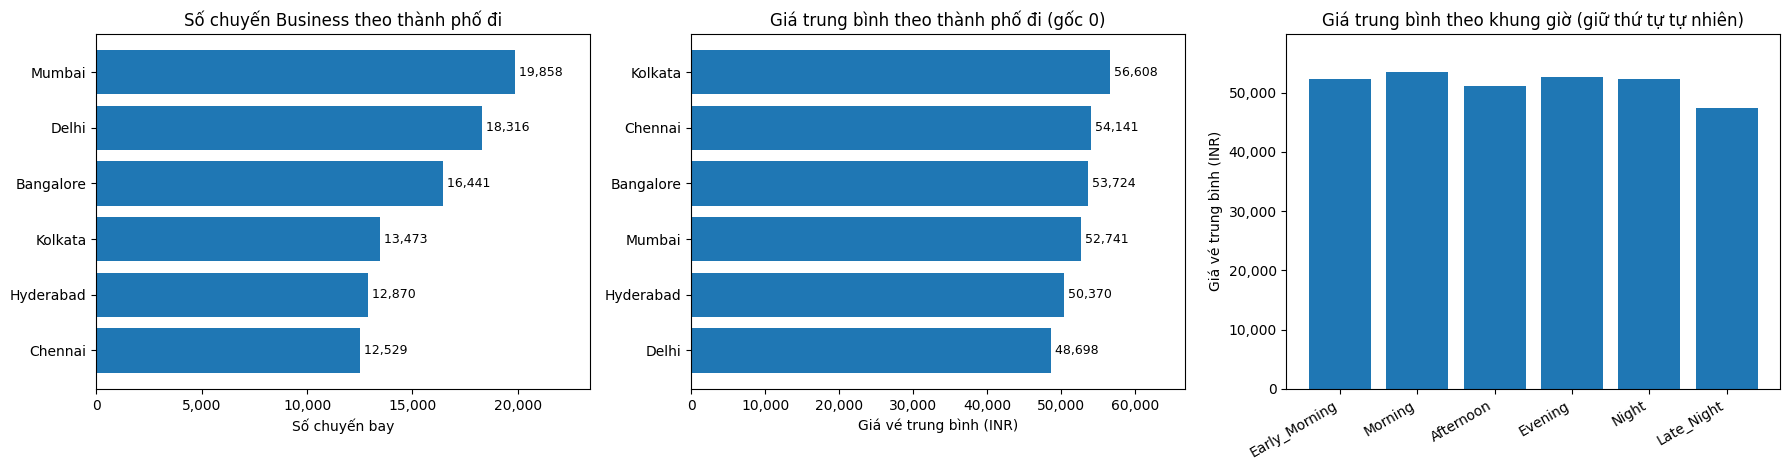

In [ ]:
import matplotlib.ticker as mtick

C_BLUE = '#1f77b4'

def thousands_fmt(x, pos):
    return f'{int(x):,}'

thousands = mtick.FuncFormatter(thousands_fmt)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

cnt = bus['source_city'].value_counts().sort_values()
axes[0].barh(cnt.index, cnt.values, color=C_BLUE)
axes[0].set_title('Số chuyến Business theo thành phố đi')
axes[0].set_xlabel('Số chuyến bay'); axes[0].xaxis.set_major_formatter(thousands)
for i, v in enumerate(cnt.values):
    axes[0].text(v, i, f' {v:,}', va='center', fontsize=9)
axes[0].set_xlim(0, cnt.max() * 1.18)

mp = bus.groupby('source_city', observed=True)['price'].mean().sort_values()
axes[1].barh(mp.index, mp.values, color=C_BLUE)
axes[1].set_title('Giá trung bình theo thành phố đi (gốc 0)')
axes[1].set_xlabel('Giá vé trung bình (INR)'); axes[1].xaxis.set_major_formatter(thousands)
for i, v in enumerate(mp.values):
    axes[1].text(v, i, f' {v:,.0f}', va='center', fontsize=9)
axes[1].set_xlim(0, mp.max() * 1.18)

mt = bus.groupby('departure_time', observed=True)['price'].mean().reindex(TIME_ORDER)
axes[2].bar(range(len(mt)), mt.values, color=C_BLUE)
axes[2].set_xticks(range(len(mt))); axes[2].set_xticklabels(mt.index, rotation=30, ha='right')
axes[2].set_title('Giá trung bình theo khung giờ (giữ thứ tự tự nhiên)')
axes[2].set_ylabel('Giá vé trung bình (INR)'); axes[2].yaxis.set_major_formatter(thousands)
axes[2].set_ylim(0, mt.max() * 1.12)
plt.tight_layout(); plt.show()

## 3.2 Biểu đồ nhóm thanh (Grouped) và xếp chồng (Stacked) – 2 biến phân loại
* **Grouped:** các thanh cạnh nhau → so sánh **nội bộ nhóm** dễ, đọc giá trị dễ (cùng gốc 0). Tối đa ~3–4 thanh/nhóm.
* **Stacked:** chỉ dùng khi **tổng có ý nghĩa thực tế** (vd: tổng số chuyến bay). **Không** xếp chồng giá trung bình/trung vị.

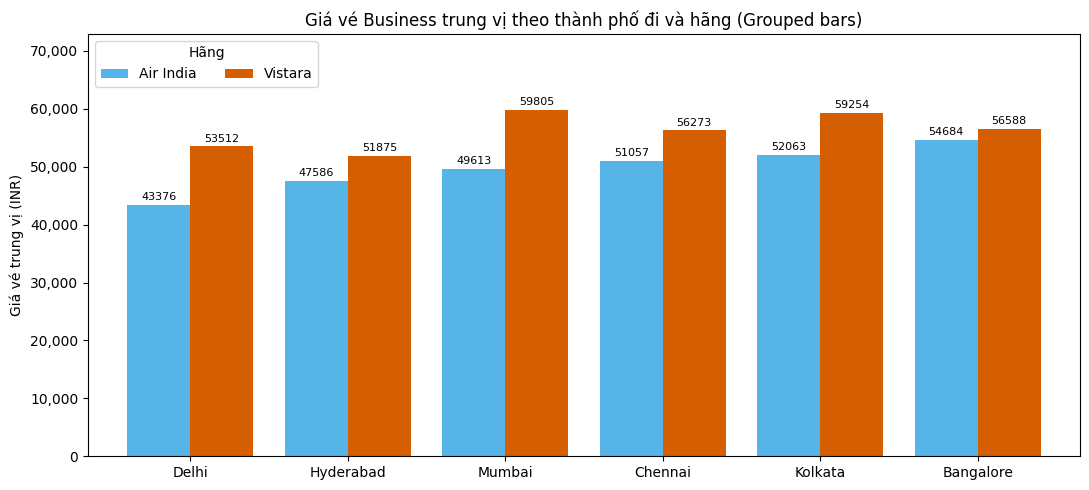

In [ ]:
# --- Grouped: giá trung vị theo thành phố đi × hãng ---
med = bus.groupby(['source_city', 'airline'], observed=True)['price'].median().unstack('airline')
med = med.sort_values(med.columns[0])

ax = med.plot.bar(figsize=(11, 5), color=[AIR_COLORS[a] for a in med.columns], width=.8)
ax.set_title('Giá vé Business trung vị theo thành phố đi và hãng (Grouped bars)')
ax.set_xlabel(''); ax.set_ylabel('Giá vé trung vị (INR)'); ax.yaxis.set_major_formatter(thousands)
plt.xticks(rotation=0)
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.0f', fontsize=8, padding=2)
ax.set_ylim(0, med.values.max() * 1.22)
ax.legend(title='Hãng', loc='upper left', ncol=2)
plt.tight_layout(); plt.show()

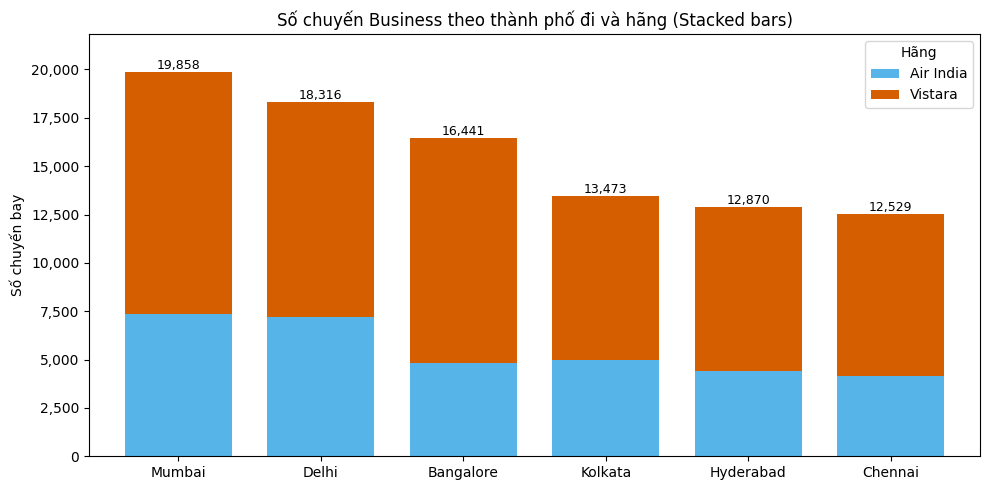

In [ ]:
# --- Stacked: tổng số chuyến theo thành phố đi × hãng (tổng = tổng số chuyến → có ý nghĩa) ---
ct = pd.crosstab(bus['source_city'], bus['airline'])
ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False).index]

ax = ct.plot.bar(stacked=True, figsize=(10, 5), color=[AIR_COLORS[a] for a in ct.columns], width=.75)
ax.set_title('Số chuyến Business theo thành phố đi và hãng (Stacked bars)')
ax.set_xlabel(''); ax.set_ylabel('Số chuyến bay'); ax.yaxis.set_major_formatter(thousands)
plt.xticks(rotation=0)
for i, (_, row) in enumerate(ct.iterrows()):
    ax.text(i, row.sum(), f'{row.sum():,}', ha='center', va='bottom', fontsize=9)
ax.set_ylim(0, ct.sum(axis=1).max() * 1.1)
ax.legend(title='Hãng')
plt.tight_layout(); plt.show()

## 3.3 Biểu đồ chấm (Dot plot) – khi thanh gây lãng phí không gian
Dùng **dấu chấm thay cho điểm kết thúc của thanh** → trục **không cần bắt đầu từ 0**, phóng to khác biệt trong dải hẹp, tiết kiệm không gian khi có nhiều danh mục (ở đây: các tuyến bay).

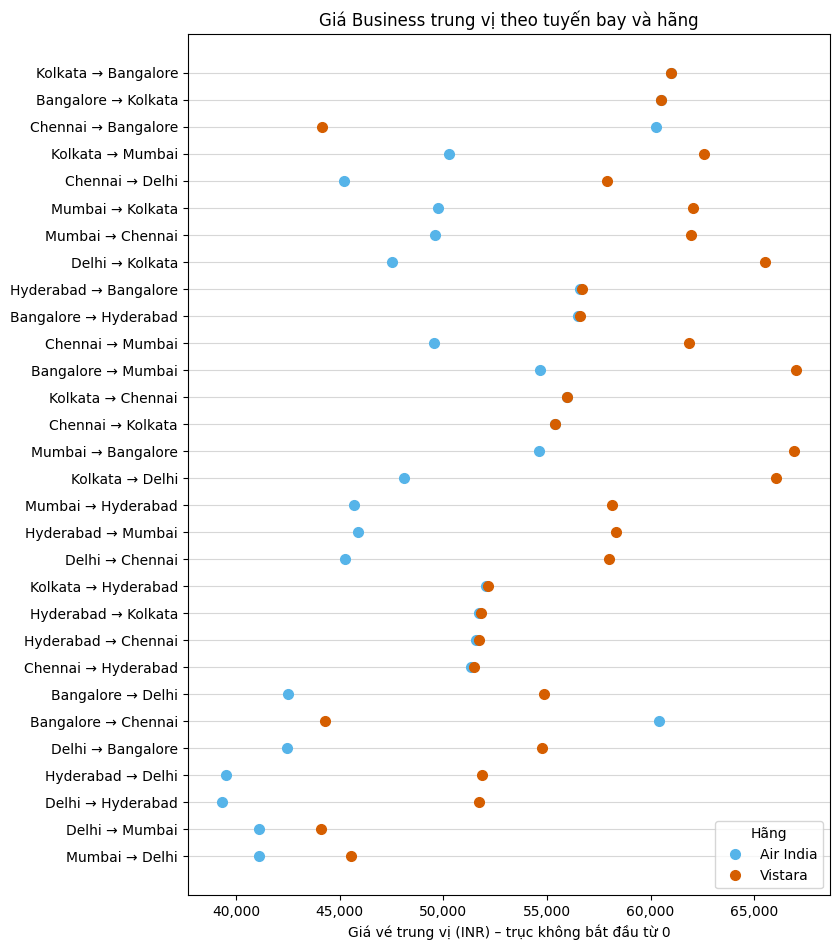

In [ ]:
rp = bus.pivot_table(index='route', columns='airline', values='price', aggfunc='median')
rp = rp.loc[bus.groupby('route', observed=True)['price'].median().sort_values().index]
n = len(rp)

fig, ax = plt.subplots(figsize=(8.5, max(5, 0.32 * n)))
y = np.arange(n)
for a in rp.columns:
    ax.plot(rp[a].values, y, 'o', color=AIR_COLORS[a], markersize=7, label=a)
ax.set_yticks(y); ax.set_yticklabels(rp.index)
allv = rp.values[~np.isnan(rp.values)]
pad = (allv.max() - allv.min()) * .06
ax.set_xlim(allv.min() - pad, allv.max() + pad)             # trục KHÔNG bắt đầu từ 0
ax.xaxis.set_major_formatter(thousands); ax.grid(axis='y', alpha=.5)
ax.set_title('Giá Business trung vị theo tuyến bay và hãng')
ax.set_xlabel('Giá vé trung vị (INR) – trục không bắt đầu từ 0')
ax.legend(title='Hãng', loc='lower right')
plt.tight_layout(); plt.show()

## 3.4 Biểu đồ nhiệt (Heatmap) – dữ liệu dạng ma trận
Ánh xạ giá trị vào **màu sắc** trên lưới 2D. Rất mạnh để nhận diện **xu hướng vĩ mô**, nhưng con người đọc giá trị chính xác qua màu kém hơn qua độ dài → luôn kèm số (annot) và dùng thang màu liên tục *viridis*.

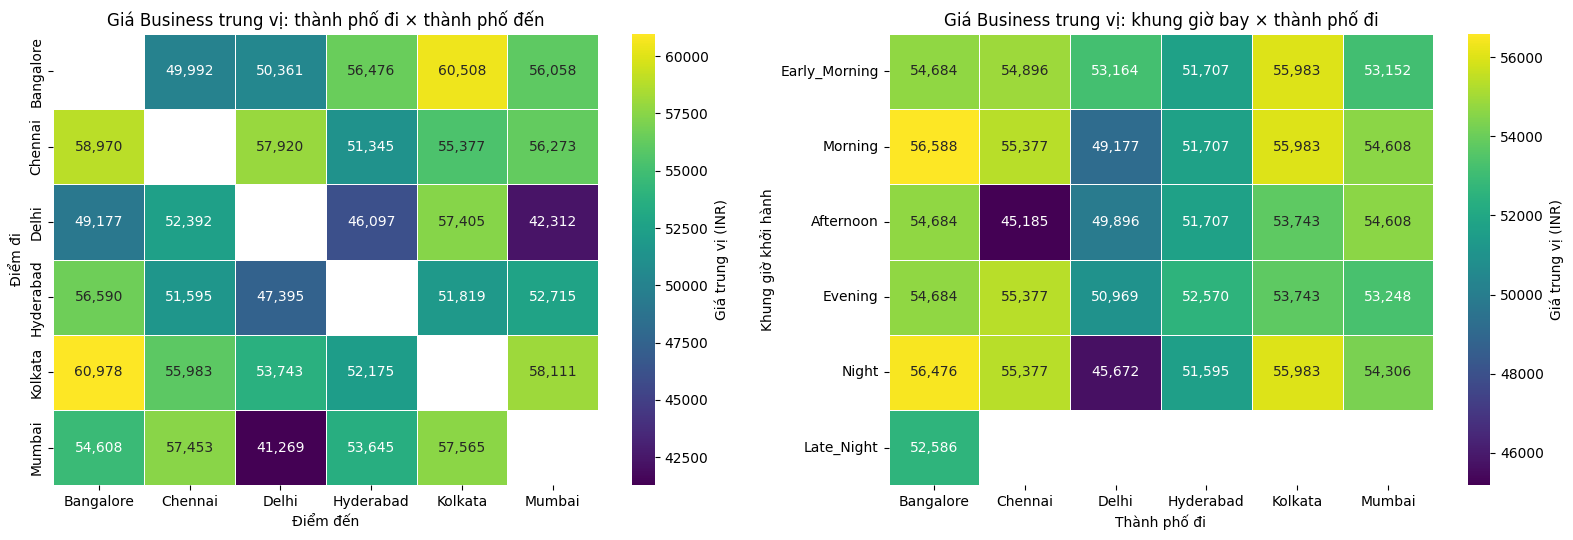

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

pv1 = bus.pivot_table(index='source_city', columns='destination_city', values='price', aggfunc='median')
sns.heatmap(pv1, annot=True, fmt=',.0f', cmap='viridis', linewidths=.5, ax=axes[0], cbar_kws={'label': 'Giá trung vị (INR)'})
axes[0].set_title('Giá Business trung vị: thành phố đi × thành phố đến')
axes[0].set_xlabel('Điểm đến'); axes[0].set_ylabel('Điểm đi')

pv2 = bus.pivot_table(index='departure_time', columns='source_city', values='price', aggfunc='median', observed=True)
sns.heatmap(pv2, annot=True, fmt=',.0f', cmap='viridis', linewidths=.5, ax=axes[1], cbar_kws={'label': 'Giá trung vị (INR)'})
axes[1].set_title('Giá Business trung vị: khung giờ bay × thành phố đi')
axes[1].set_xlabel('Thành phố đi'); axes[1].set_ylabel('Khung giờ khởi hành')
plt.tight_layout(); plt.show()


### Cây quyết định chọn biểu đồ số lượng (áp dụng cho dữ liệu Business)

| Tình huống | Biểu đồ đã chọn | Lý do |
|---|---|---|
| 1 biến phân loại, trục buộc từ 0 | Bar chart (3.1) | Ít danh mục, so sánh độ dài chính xác |
| 1 biến phân loại, nhiều danh mục, cần phóng to dải hẹp | Dot plot (3.3) | Nhiều tuyến bay, không cần gốc 0 |
| 2 biến phân loại, chỉ so sánh nội bộ | Grouped bars (3.2) | Trung vị giá không cộng được → không xếp chồng |
| 2 biến phân loại, tổng có ý nghĩa | Stacked bars (3.2) | Tổng = tổng số chuyến |
| 2 biến phân loại dạng ma trận lớn | Heatmap (3.4) | 6×6 tuyến bay / 6×6 giờ–thành phố |

---
# 4. MỤC 1.7 – 1.8 – TRỰC QUAN HÓA PHÂN PHỐI
Khi có hàng nghìn điểm liên tục (giá vé, thời gian bay), mục tiêu là thấy **hình dáng tổng thể** của dữ liệu thay vì từng điểm rời rạc.

## 4.1 Histogram – luôn thử nhiều binwidth
Histogram nhóm dữ liệu thành các khoảng (bin) **cùng độ rộng**. Binwidth quá lớn che giấu chi tiết, quá nhỏ tạo nhiễu.

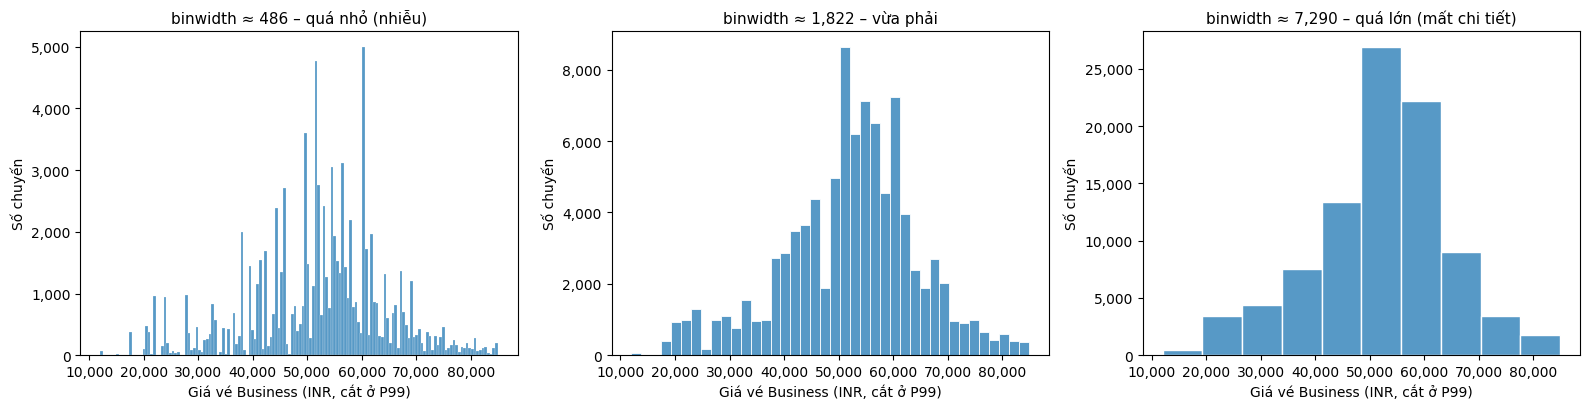

In [ ]:
x = bus['price']
hi = x.quantile(.99)                     # cắt ở P99 chỉ để hiển thị cho rõ phần thân
xs_ = x[x <= hi]
rng_ = hi - x.min()
widths = [rng_ / 150, rng_ / 40, rng_ / 10]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, w, tag in zip(axes, widths, ['quá nhỏ (nhiễu)', 'vừa phải', 'quá lớn (mất chi tiết)']):
    sns.histplot(xs_, binwidth=w, color=C_BLUE, edgecolor='white', ax=ax)
    ax.set_title(f'binwidth ≈ {w:,.0f} – {tag}', fontsize=11)
    ax.set_xlabel('Giá vé Business (INR, cắt ở P99)'); ax.set_ylabel('Số chuyến')
    ax.xaxis.set_major_formatter(thousands); ax.yaxis.set_major_formatter(thousands)
plt.tight_layout(); plt.show()

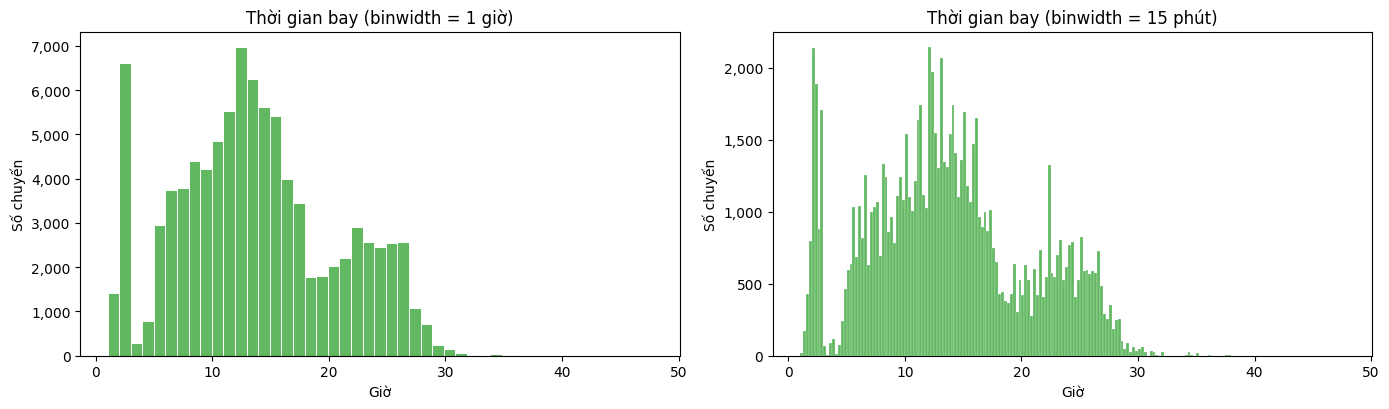

In [ ]:
C_GREEN = '#2ca02c'

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sns.histplot(bus['duration'], binwidth=1, color=C_GREEN, edgecolor='white', ax=axes[0])
axes[0].set_title('Thời gian bay (binwidth = 1 giờ)'); axes[0].set_xlabel('Giờ'); axes[0].set_ylabel('Số chuyến')
sns.histplot(bus['duration'], binwidth=.25, color=C_GREEN, edgecolor='white', ax=axes[1])
axes[1].set_title('Thời gian bay (binwidth = 15 phút)'); axes[1].set_xlabel('Giờ'); axes[1].set_ylabel('Số chuyến')
for ax in axes: ax.yaxis.set_major_formatter(thousands)
plt.tight_layout(); plt.show()

## 4.2 Density plot (KDE) và “dữ liệu ảo”
KDE đặt một đường cong nhỏ (Gaussian) tại **mỗi** điểm dữ liệu rồi cộng dồn.  Nếu cho phép đuôi kéo dài (`cut > 0`), KDE có thể mở rộng vào **vùng phi lý** (vd: giá vé âm) và kết quả còn phụ thuộc **băng thông (bandwidth)**.

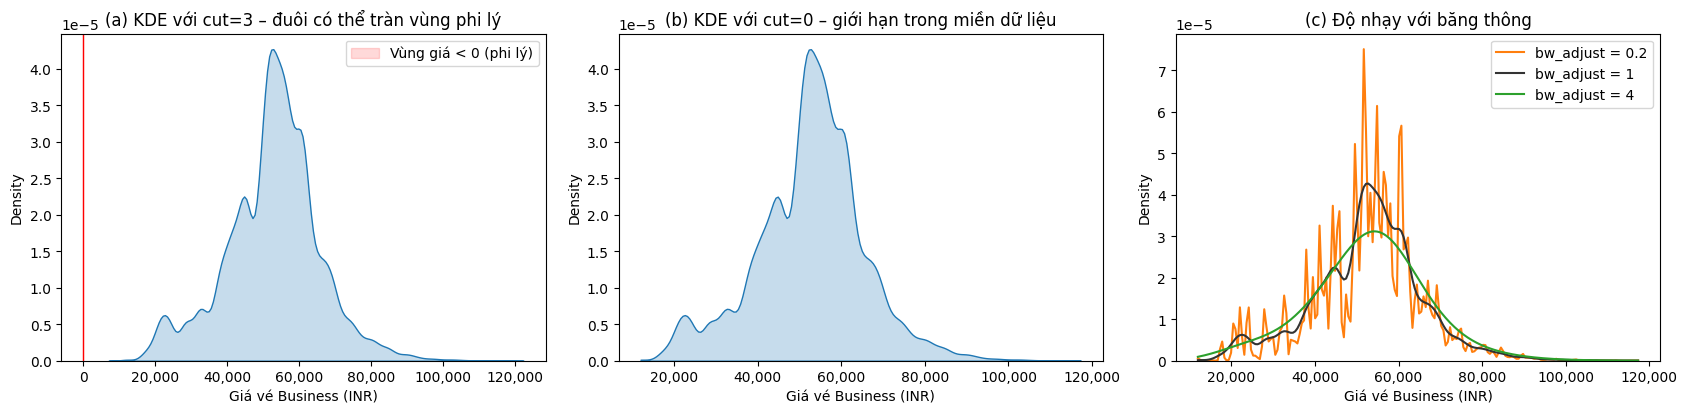

In [ ]:
C_ORANGE = '#ff7f0e'
C_DARK = '#333333'

xk = bus_s['price']
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))

sns.kdeplot(xk, cut=3, fill=True, color=C_BLUE, ax=axes[0])
xl = axes[0].get_xlim()
axes[0].axvspan(min(xl[0], 0), 0, color='red', alpha=.15, label='Vùng giá < 0 (phi lý)')
axes[0].axvline(0, color='red', lw=1)
axes[0].set_title('(a) KDE với cut=3 – đuôi có thể tràn vùng phi lý'); axes[0].legend()

sns.kdeplot(xk, cut=0, fill=True, color=C_BLUE, ax=axes[1])
axes[1].set_title('(b) KDE với cut=0 – giới hạn trong miền dữ liệu')

for adj, col in zip([0.2, 1, 4], [C_ORANGE, C_DARK, C_GREEN]):
    sns.kdeplot(xk, bw_adjust=adj, cut=0, color=col, label=f'bw_adjust = {adj}', ax=axes[2])
axes[2].set_title('(c) Độ nhạy với băng thông'); axes[2].legend()

for ax in axes:
    ax.set_xlabel('Giá vé Business (INR)'); ax.xaxis.set_major_formatter(thousands)
plt.tight_layout(); plt.show()

## 4.3 So sánh đối chiếu: Histogram vs Density

| | Histogram | Density plot |
|---|---|---|
| Bản chất | Chân thực, đếm trực tiếp | Ước lượng, làm mượt |
| Ưu điểm | Dễ giải thích; không tạo giá trị phi lý | Mượt, thẩm mỹ; dễ so sánh nhiều phân phối đè lên |
| Nhược điểm | Phụ thuộc kích thước bin | Phụ thuộc băng thông; ảo giác ở phần đuôi |

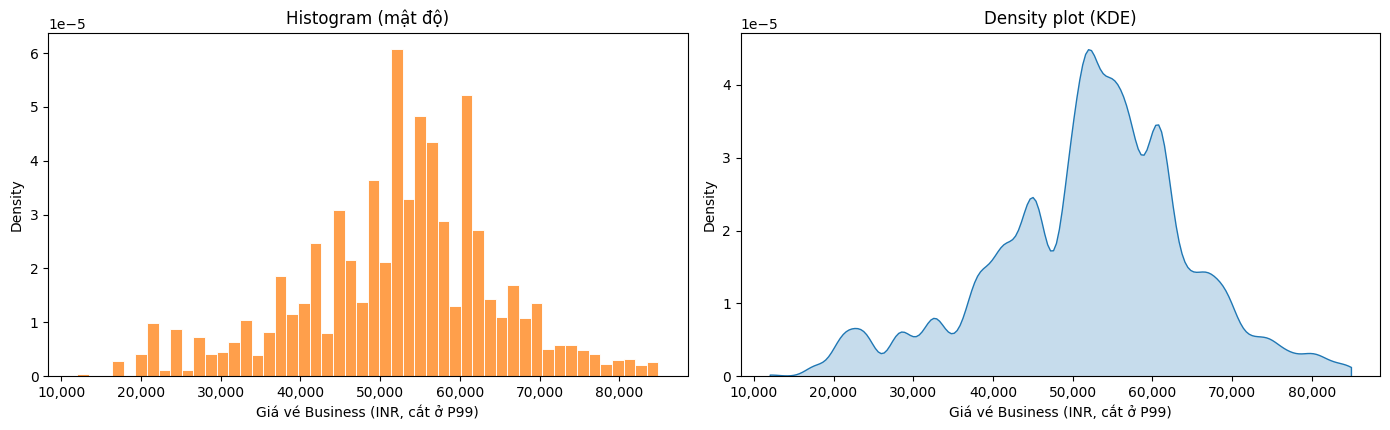

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharex=True)
sns.histplot(xs_, bins=50, stat='density', color=C_ORANGE, edgecolor='white', ax=axes[0])
axes[0].set_title('Histogram (mật độ)')
sns.kdeplot(xs_, cut=0, fill=True, color=C_BLUE, ax=axes[1])
axes[1].set_title('Density plot (KDE)')
for ax in axes:
    ax.set_xlabel('Giá vé Business (INR, cắt ở P99)'); ax.xaxis.set_major_formatter(thousands)
plt.tight_layout(); plt.show()

## 4.4 Thử thách: trực quan hóa 2 phân phối cùng lúc (giữa hai hãng bay)
**Cách làm sai:** histogram xếp chồng (stacked) – cột của nhóm trên không bắt đầu từ cùng đường cơ sở nên không thể so sánh.
**Hai giải pháp:** (1) **mật độ đè nhau** (2–4 nhóm); (2) **kim tự tháp** – hai histogram quay lưng vào nhau (đúng 2 nhóm).

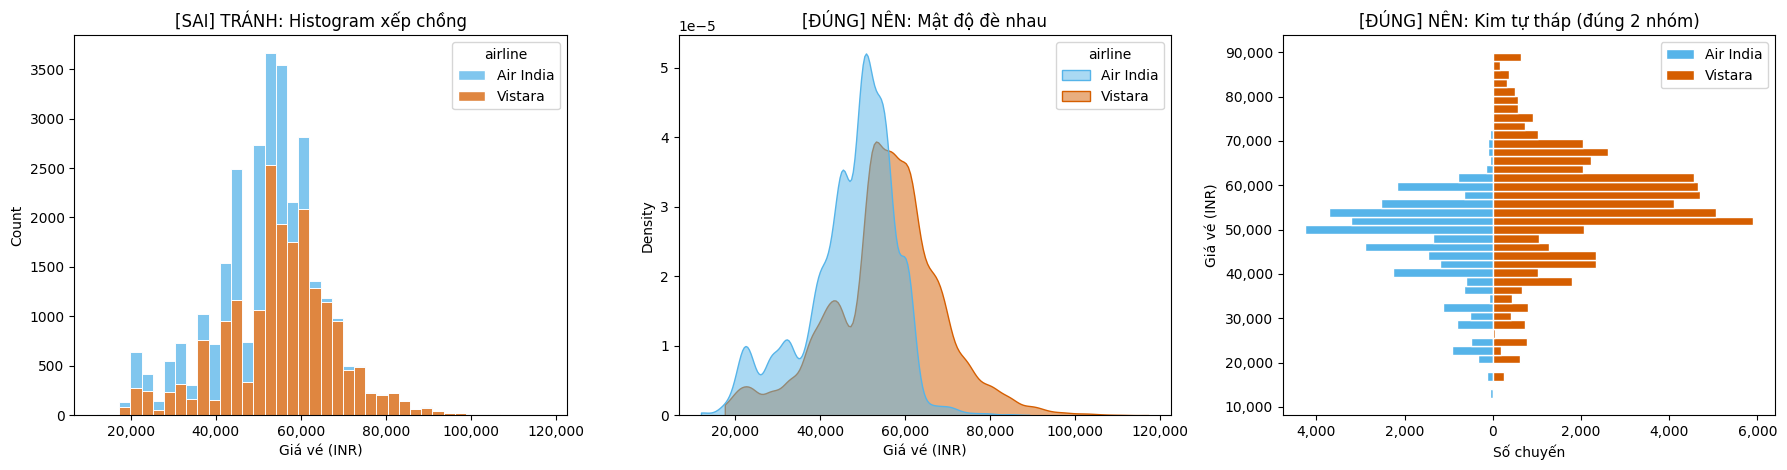

In [ ]:
a1, a2 = airlines[0], airlines[1]
g1, g2 = bus[bus['airline'] == a1], bus[bus['airline'] == a2]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

sns.histplot(data=bus_s[bus_s['airline'].isin([a1, a2])], x='price', hue='airline', hue_order=[a1, a2], palette=AIR_COLORS,
             multiple='stack', bins=40, edgecolor='white', ax=axes[0])
axes[0].set_title('[SAI] TRÁNH: Histogram xếp chồng'); axes[0].set_xlabel('Giá vé (INR)')
axes[0].xaxis.set_major_formatter(thousands)

sns.kdeplot(data=bus_s[bus_s['airline'].isin([a1, a2])], x='price', hue='airline', hue_order=[a1, a2], palette=AIR_COLORS,
            common_norm=False, fill=True, alpha=.5, cut=0, ax=axes[1])
axes[1].set_title('[ĐÚNG] NÊN: Mật độ đè nhau'); axes[1].set_xlabel('Giá vé (INR)')
axes[1].xaxis.set_major_formatter(thousands)

lo_, hi_ = bus['price'].min(), bus['price'].quantile(.995)
bins_ = np.linspace(lo_, hi_, 41)
c1, _ = np.histogram(g1['price'].clip(upper=hi_), bins=bins_)
c2, _ = np.histogram(g2['price'].clip(upper=hi_), bins=bins_)
mid, hgt = (bins_[:-1] + bins_[1:]) / 2, np.diff(bins_)
axes[2].barh(mid, -c1, height=hgt, color=AIR_COLORS[a1], edgecolor='white', label=a1)
axes[2].barh(mid,  c2, height=hgt, color=AIR_COLORS[a2], edgecolor='white', label=a2)
axes[2].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{abs(v):,.0f}'))
axes[2].yaxis.set_major_formatter(thousands)
axes[2].set_title('[ĐÚNG] NÊN: Kim tự tháp (đúng 2 nhóm)'); axes[2].set_xlabel('Số chuyến'); axes[2].set_ylabel('Giá vé (INR)')
axes[2].legend()
plt.tight_layout(); plt.show()

## 4.5 ECDF – hàm phân phối tích lũy: sự trung thực tuyệt đối
ECDF xếp hạng mọi điểm dữ liệu từ thấp đến cao: trục X là giá trị thực, trục Y là tỷ lệ tích lũy (0 → 1). **Không cần chọn bin, không tham số ẩn, mọi điểm đều có mặt.** Đọc bách phân vị bằng cách kéo ngang từ trục Y.

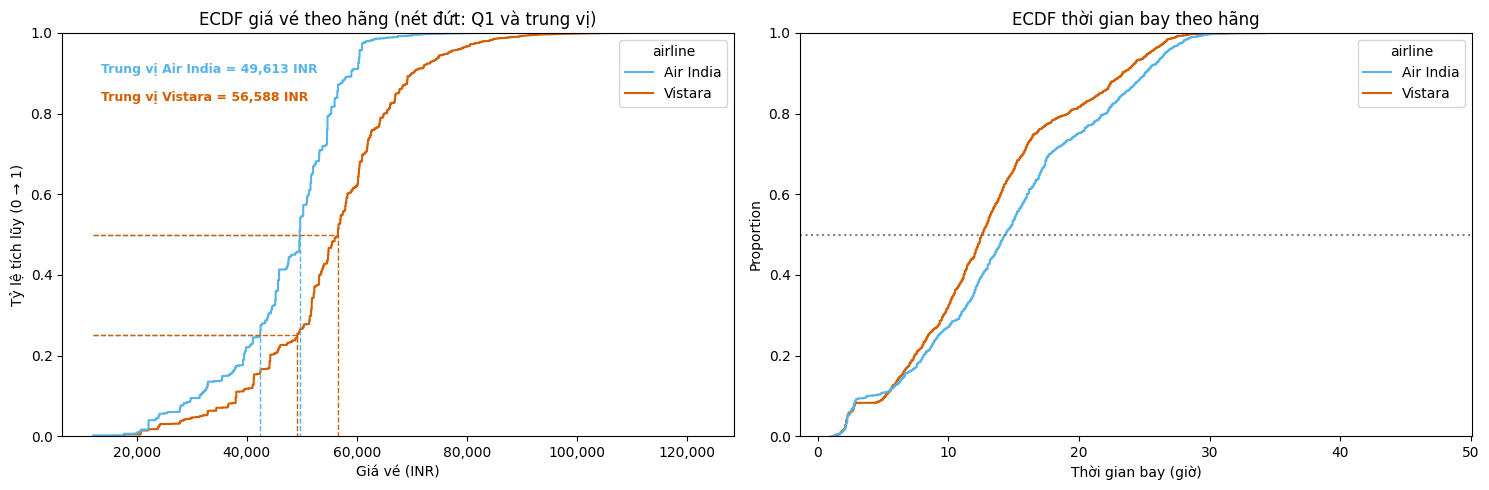

Bách phân vị của giá vé Business (INR):


,0.05,0.25,0.50,0.75,0.95,0.99
airline,,,,,,
Air India,23944.0,42457.0,49613.0,54608.0,60508.0,67421.0
Vistara,31982.0,49207.0,56588.0,62591.0,76677.0,88916.0


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.ecdfplot(data=bus, x='price', hue='airline', hue_order=airlines, palette=AIR_COLORS, ax=axes[0])
for k, (a, g) in enumerate(bus.groupby('airline', observed=True)):
    q25, q50 = g['price'].quantile([.25, .5])
    col = AIR_COLORS[a]
    for q, p in [(q25, .25), (q50, .5)]:
        axes[0].plot([bus['price'].min(), q, q], [p, p, 0], color=col, ls='--', lw=1)
    axes[0].text(bus['price'].min() + 1500, .90 - .07 * k, f'Trung vị {a} = {q50:,.0f} INR', fontsize=9, color=col, fontweight='bold')
axes[0].set_title('ECDF giá vé theo hãng (nét đứt: Q1 và trung vị)')
axes[0].set_xlabel('Giá vé (INR)'); axes[0].set_ylabel('Tỷ lệ tích lũy (0 → 1)')
axes[0].xaxis.set_major_formatter(thousands)

sns.ecdfplot(data=bus, x='duration', hue='airline', hue_order=airlines, palette=AIR_COLORS, ax=axes[1])
axes[1].axhline(.5, color='gray', ls=':')
axes[1].set_title('ECDF thời gian bay theo hãng'); axes[1].set_xlabel('Thời gian bay (giờ)')
plt.tight_layout(); plt.show()

print('Bách phân vị của giá vé Business (INR):')
display(bus.groupby('airline', observed=True)['price'].quantile([.05, .25, .5, .75, .95, .99]).unstack().round(0))

## 4.6 Dữ liệu lệch cao (Highly skewed) → Biến đổi logarit
Với dữ liệu đuôi dài, vài giá trị rất lớn ép phần lớn dữ liệu sát gốc. Giải pháp: `scale_x_log10()`.
* **Pattern 1 – Log-normal:** trên thang log hiện đường cong chuông chuẩn.
* **Pattern 2 – Power-law:** CCDF trên thang **log-log** là một đường thẳng.

*Lưu ý:* giá Business có thể **ít lệch hơn** giá Economy; hãy đọc chỉ số skew trước khi kết luận có cần log hay không.

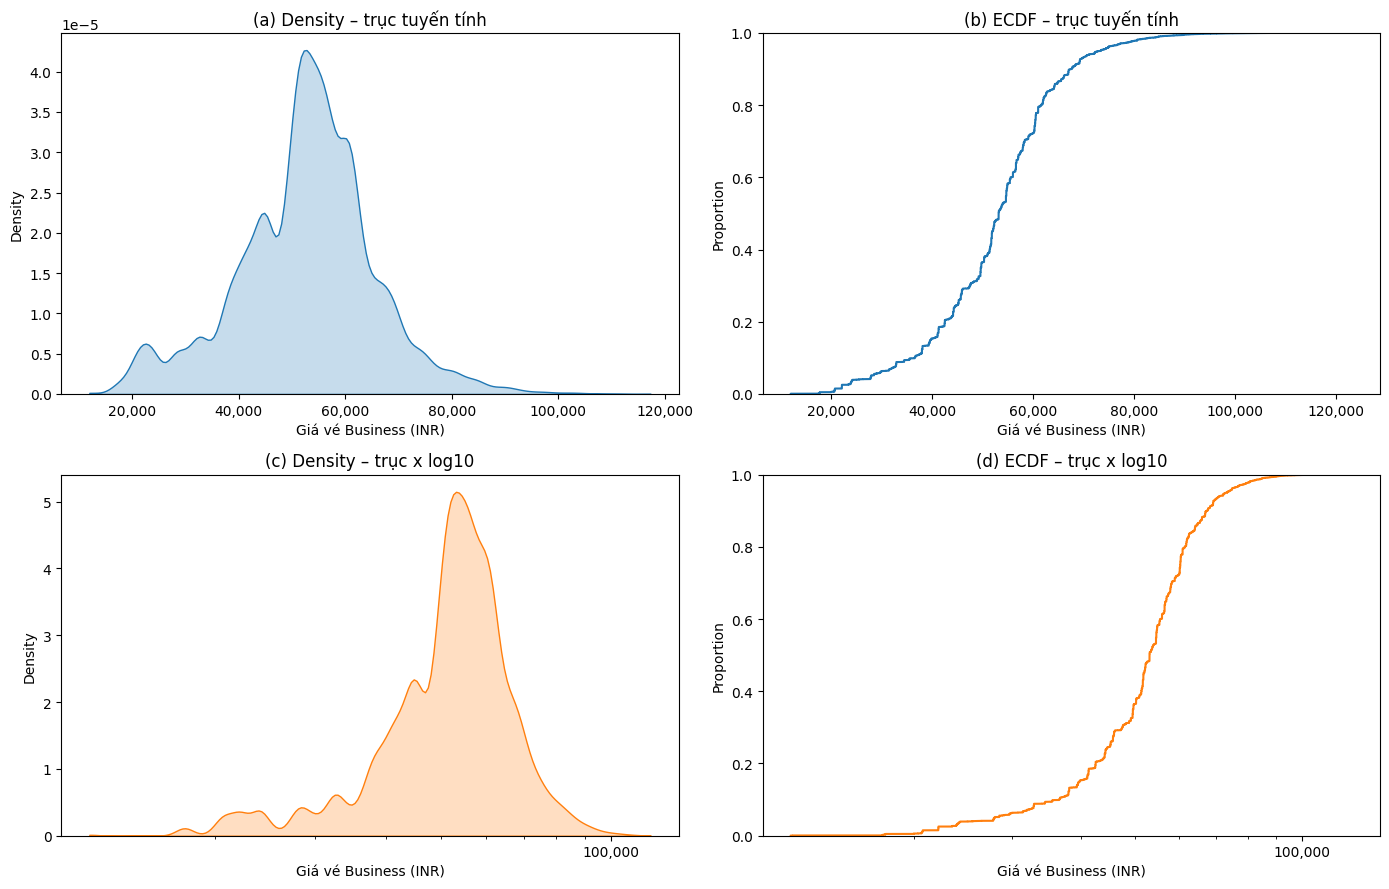

,Độ lệch (skew) – giá gốc,Độ lệch (skew) – log10(giá)
airline,,
Air India,-0.746344,-1.531075
Vistara,-0.152848,-1.272367
Toàn bộ Business,-0.095236,-1.207584


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.kdeplot(bus_s['price'], fill=True, color=C_BLUE, cut=0, ax=axes[0, 0]);  axes[0, 0].set_title('(a) Density – trục tuyến tính')
sns.ecdfplot(bus['price'], color=C_BLUE, ax=axes[0, 1]);                     axes[0, 1].set_title('(b) ECDF – trục tuyến tính')
sns.kdeplot(bus_s['price'], fill=True, color=C_ORANGE, cut=0, log_scale=True, ax=axes[1, 0]); axes[1, 0].set_title('(c) Density – trục x log10')
sns.ecdfplot(bus['price'], color=C_ORANGE, log_scale=True, ax=axes[1, 1]);   axes[1, 1].set_title('(d) ECDF – trục x log10')
for ax in axes.ravel():
    ax.set_xlabel('Giá vé Business (INR)'); ax.xaxis.set_major_formatter(thousands)
plt.tight_layout(); plt.show()

sk = pd.DataFrame({'Độ lệch (skew) – giá gốc': bus.groupby('airline', observed=True)['price'].apply(stats.skew),
                   'Độ lệch (skew) – log10(giá)': bus.groupby('airline', observed=True)['price_log10'].apply(stats.skew)})
sk.loc['Toàn bộ Business'] = [stats.skew(bus['price']), stats.skew(bus['price_log10'])]
display(sk)

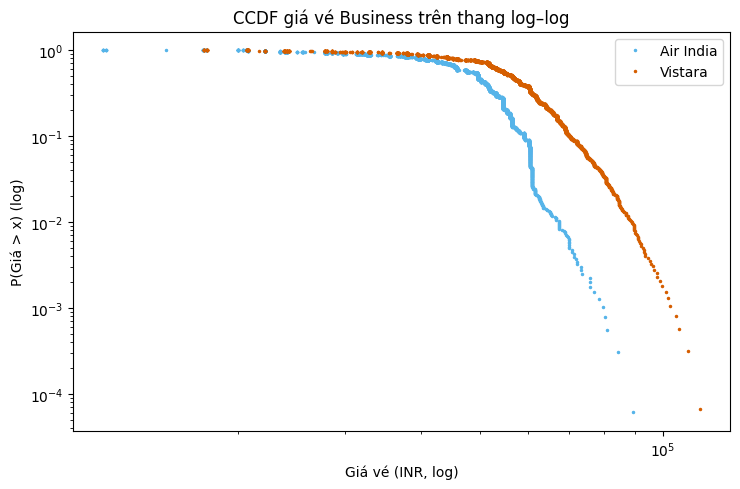

Nếu các điểm KHÔNG nằm trên một đường thẳng → giá vé không tuân theo power-law.


In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for a, g in bus.groupby('airline', observed=True):
    v = np.sort(g['price'].values)
    ccdf = 1 - np.arange(len(v)) / len(v)
    step = max(1, len(v) // 4000)
    ax.loglog(v[::step], ccdf[::step], '.', ms=3, color=AIR_COLORS[a], label=a)
ax.set_title('CCDF giá vé Business trên thang log–log')
ax.set_xlabel('Giá vé (INR, log)'); ax.set_ylabel('P(Giá > x) (log)')
ax.legend(); plt.tight_layout(); plt.show()
print('Nếu các điểm KHÔNG nằm trên một đường thẳng → giá vé không tuân theo power-law.')

## 4.7 Biểu đồ Q-Q – thực tế đối đầu lý thuyết
Q-Q plot **không dùng để xem hình dáng**, mà để kiểm tra dữ liệu thực tế có tuân theo phân phối lý thuyết (thường là chuẩn) hay không. **Quy tắc vàng:** điểm nằm trên đường chéo ⇒ khớp; cong ở hai đầu ⇒ đuôi nặng/nhẹ hơn chuẩn.

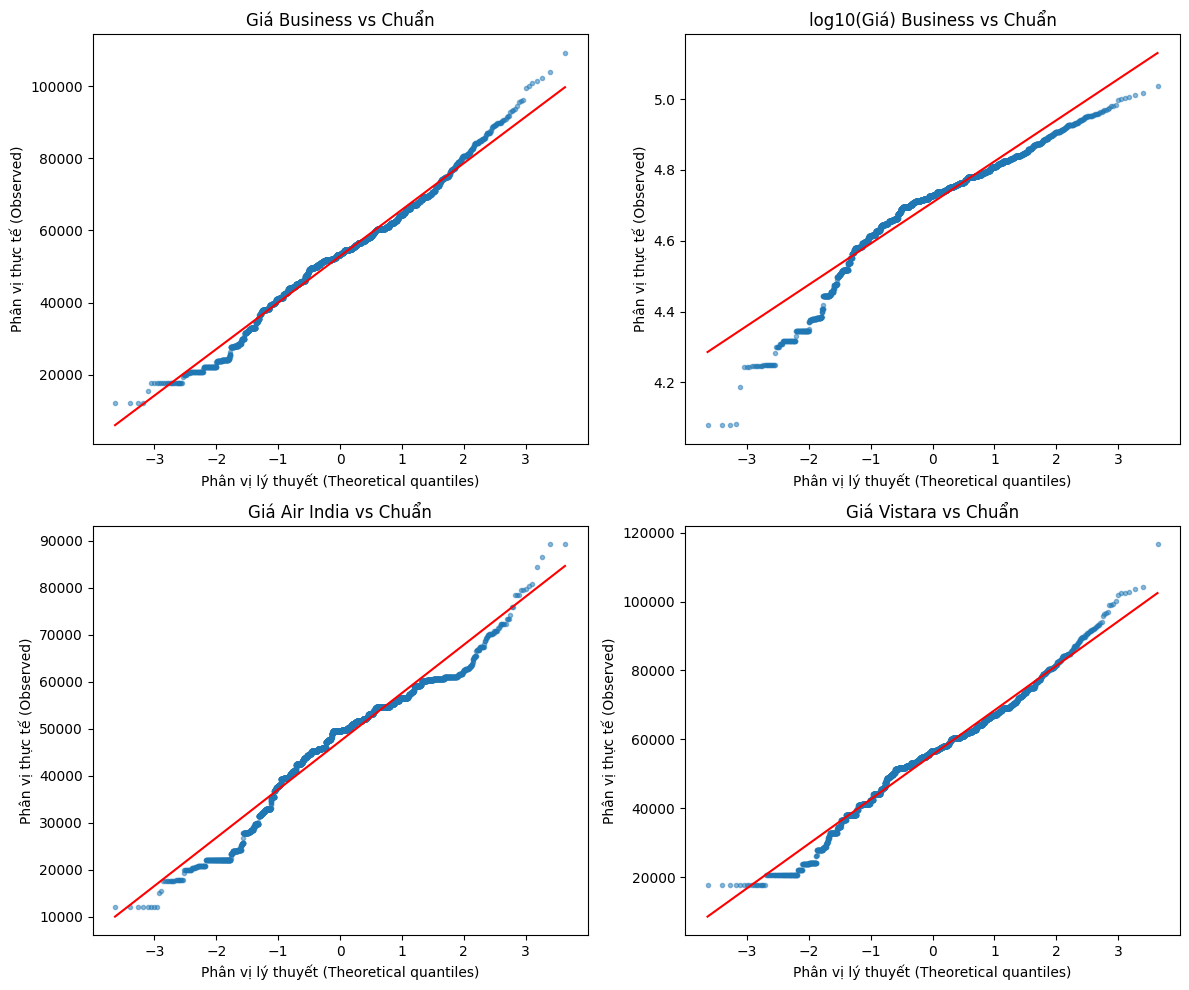

,skew,kurtosis dư
Giá Business,-0.095236,0.810253
log10 Giá Business,-1.207584,2.277197


In [ ]:
items = [(bus_s['price'], 'Giá Business vs Chuẩn'),
         (bus_s['price_log10'], 'log10(Giá) Business vs Chuẩn')]
for a in airlines[:2]:
    items.append((bus_s.loc[bus_s['airline'] == a, 'price'], f'Giá {a} vs Chuẩn'))

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (vals, title) in zip(axes.ravel(), items):
    stats.probplot(vals.sample(min(len(vals), 5000), random_state=1), dist='norm', plot=ax)
    ax.get_lines()[0].set(markersize=3, alpha=.5, color=C_BLUE)
    ax.get_lines()[1].set(color='red', lw=1.5)
    ax.set_title(title)
    ax.set_xlabel('Phân vị lý thuyết (Theoretical quantiles)'); ax.set_ylabel('Phân vị thực tế (Observed)')
plt.tight_layout(); plt.show()

kt = pd.DataFrame({'skew': [stats.skew(bus['price']), stats.skew(bus['price_log10'])],
                   'kurtosis dư': [stats.kurtosis(bus['price']), stats.kurtosis(bus['price_log10'])]},
                  index=['Giá Business', 'log10 Giá Business'])
display(kt)

### Ma trận lựa chọn biểu đồ phân phối

| Biểu đồ | Phù hợp nhất | Cẩn thận với |
|---|---|---|
| Histogram | Khám phá ban đầu, trình bày đại chúng | Kích thước bin |
| Density | So sánh mượt 2–4 nhóm đè nhau | Dữ liệu ảo ở đuôi, băng thông |
| ECDF | Đọc bách phân vị nhanh, trung thực 100% | Khó hiểu với khán giả không chuyên |
| Q-Q | Xác nhận phân phối chuẩn / log-normal | Không dùng để thuyết trình kinh doanh thông thường |

---
# 5. MỤC 1.9 – BIỂU DIỄN NHIỀU PHÂN PHỐI CÙNG LÚC
**Khung tư duy:** gán **biến nhóm** vào một trục và **biến phản ứng** vào trục còn lại. Ở đây biến phản ứng = *giá vé Business*; biến nhóm = *thành phố đi*, *khung giờ*, *số điểm dừng*, *thời gian*.

## 5.1 Cách làm xấu: thanh sai số (mean ± SD)
Mơ hồ (SD hay sai số chuẩn?), giả định phân phối đối xứng, và **che giấu hình dạng thực** của dữ liệu.

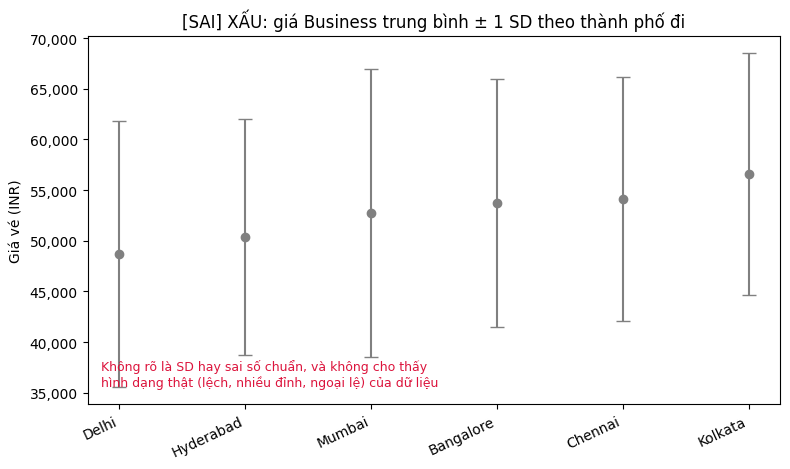

In [ ]:
order = bus.groupby('source_city', observed=True)['price'].median().sort_values().index.tolist()
g = bus.groupby('source_city', observed=True)['price'].agg(['mean', 'std']).loc[order]

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.errorbar(range(len(g)), g['mean'], yerr=g['std'], fmt='o', color='gray', capsize=5)
ax.set_xticks(range(len(g))); ax.set_xticklabels(order, rotation=25, ha='right')
ax.set_title('[SAI] XẤU: giá Business trung bình ± 1 SD theo thành phố đi')
ax.set_ylabel('Giá vé (INR)'); ax.yaxis.set_major_formatter(thousands)
ax.text(.02, .04, 'Không rõ là SD hay sai số chuẩn, và không cho thấy\nhình dạng thật (lệch, nhiều đỉnh, ngoại lệ) của dữ liệu',
        transform=ax.transAxes, va='bottom', fontsize=9, color='crimson')
plt.tight_layout(); plt.show()

## 5.2 Trục dọc – bộ công cụ tiêu chuẩn: Strip · Box · Violin
* **Strip chart:** tốt cho bộ dữ liệu nhỏ; dùng *jitter* tránh chồng điểm. * **Boxplot:** tóm tắt & làm nổi ngoại lệ. * **Violin:** hình dạng phân phối thực tế, tốt cho dữ liệu lớn.

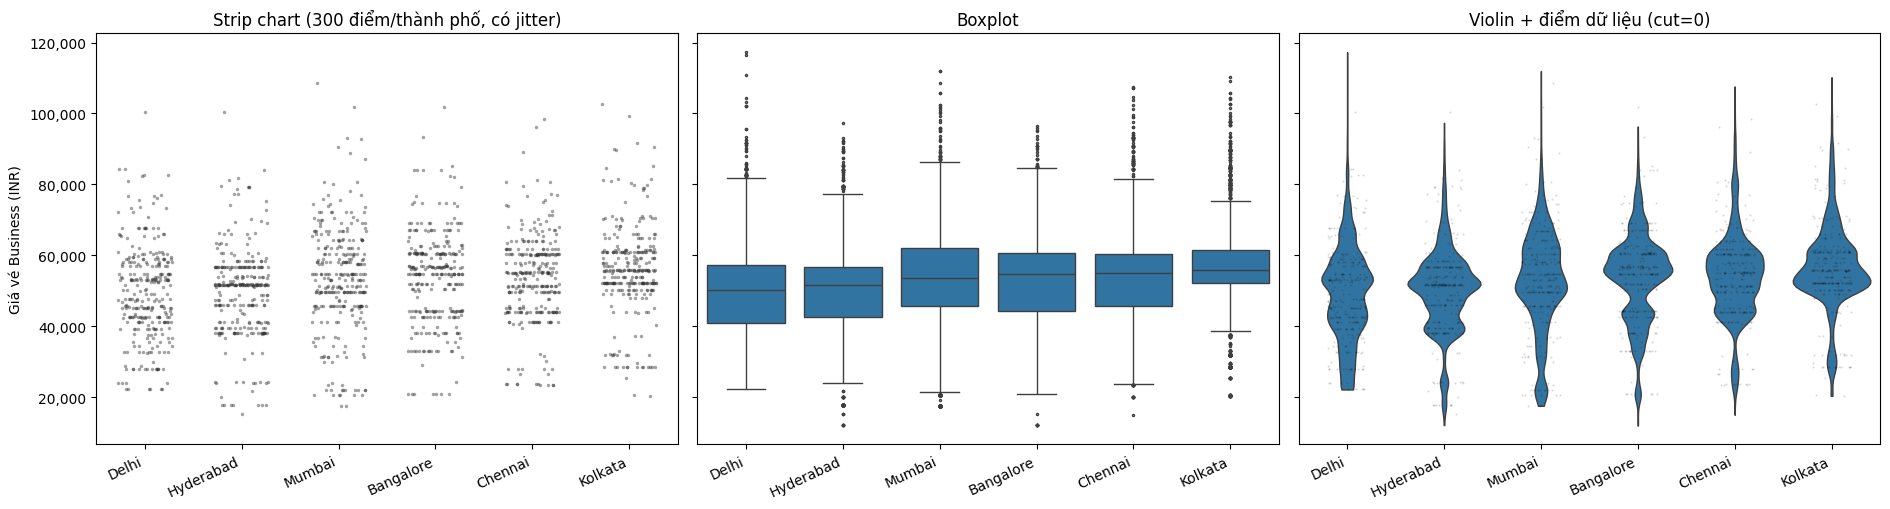

In [ ]:
strip_df = bus.sample(frac=1, random_state=1).groupby('source_city', observed=True).head(300)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.2), sharey=True)
sns.stripplot(data=strip_df, x='source_city', y='price', order=order, jitter=.28, alpha=.45, size=2.5, color=C_DARK, ax=axes[0])
axes[0].set_title('Strip chart (300 điểm/thành phố, có jitter)')
sns.boxplot(data=bus_s, x='source_city', y='price', order=order, color=C_BLUE, fliersize=1.5, linewidth=1, ax=axes[1])
axes[1].set_title('Boxplot')
sns.violinplot(data=bus_s, x='source_city', y='price', order=order, color=C_BLUE, cut=0, inner=None, linewidth=1, ax=axes[2])
sns.stripplot(data=strip_df, x='source_city', y='price', order=order, jitter=.2, alpha=.15, size=1.5, color='k', ax=axes[2])
axes[2].set_title('Violin + điểm dữ liệu (cut=0)')
for ax in axes:
    ax.set_xlabel(''); ax.set_ylabel('Giá vé Business (INR)'); ax.yaxis.set_major_formatter(thousands)
    plt.setp(ax.get_xticklabels(), rotation=25, ha='right')
plt.tight_layout(); plt.show()

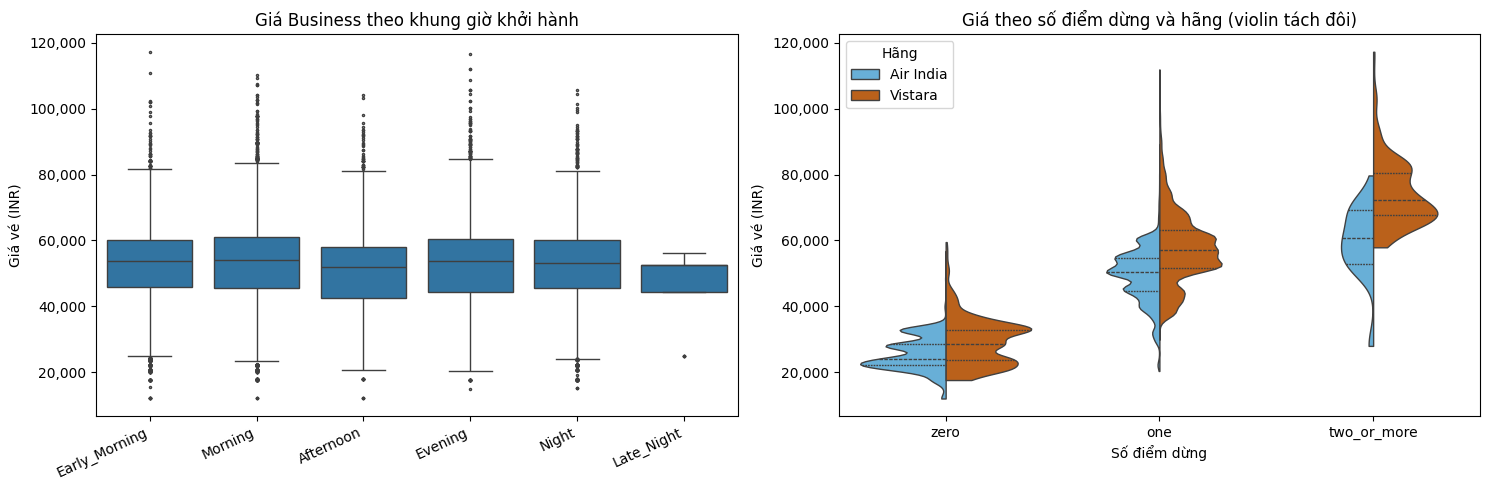

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=bus_s, x='departure_time', y='price', order=TIME_ORDER, color=C_BLUE, fliersize=1.5, linewidth=1, ax=axes[0])
axes[0].set_title('Giá Business theo khung giờ khởi hành')
axes[0].set_xlabel(''); axes[0].set_ylabel('Giá vé (INR)'); axes[0].yaxis.set_major_formatter(thousands)
plt.setp(axes[0].get_xticklabels(), rotation=25, ha='right')

two = bus_s[bus_s['airline'].isin([a1, a2])]
sns.violinplot(data=two, x='stops', y='price', hue='airline', hue_order=[a1, a2], order=STOPS_ORDER,
               palette=AIR_COLORS, split=True, cut=0, inner='quartile', linewidth=1, ax=axes[1])
axes[1].set_title('Giá theo số điểm dừng và hãng (violin tách đôi)')
axes[1].set_xlabel('Số điểm dừng'); axes[1].set_ylabel('Giá vé (INR)'); axes[1].yaxis.set_major_formatter(thousands)
axes[1].legend(title='Hãng')
plt.tight_layout(); plt.show()

## 5.3 Trục ngang – Ridgeline (sườn núi)
Sắp xếp các phân phối dọc theo trục ngang, xếp chồng theo chiều dọc: **lựa chọn hoàn hảo để thấy dịch chuyển đỉnh phân phối theo thời gian**.

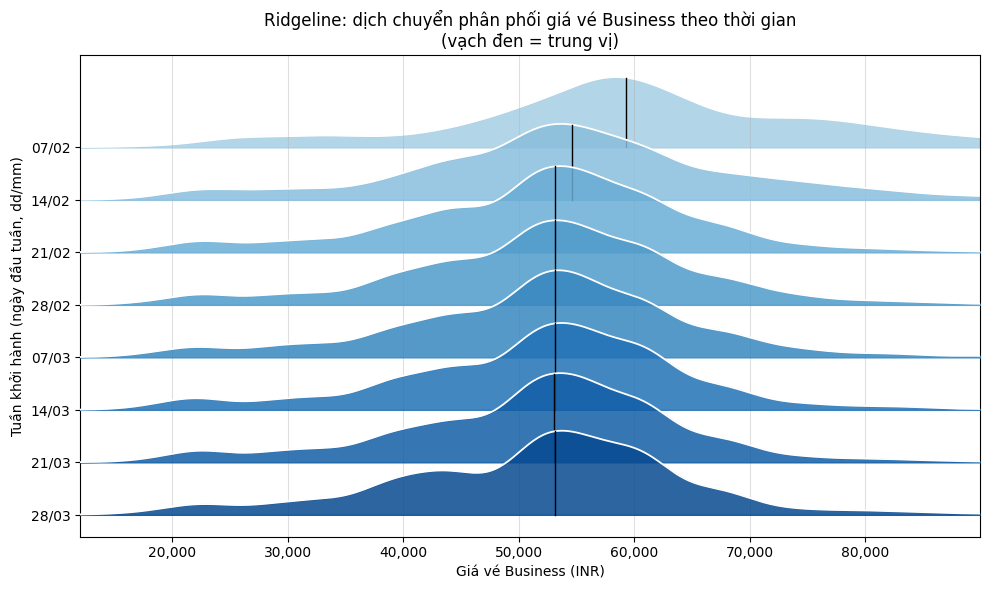

In [ ]:
def ridgeline(data, value_col, group_col, order, xlim, cmap='Blues', overlap=1.7, n_per=4000, ax=None, xlabel=''):
    ax = ax or plt.gca()
    xs = np.linspace(xlim[0], xlim[1], 400)
    dens, meds = {}, {}
    for gname in order:
        vals = data.loc[data[group_col].astype(str) == str(gname), value_col].dropna().values
        if len(vals) < 10:
            continue
        if len(vals) > n_per:
            vals = np.random.default_rng(0).choice(vals, n_per, replace=False)
        dens[gname], meds[gname] = stats.gaussian_kde(vals)(xs), np.median(vals)
    step = max(d.max() for d in dens.values()) / overlap
    colors = plt.get_cmap(cmap)(np.linspace(.35, .9, len(dens)))
    n = len(dens)
    for i, (gname, d) in enumerate(dens.items()):
        base = (n - 1 - i) * step
        ax.fill_between(xs, base, base + d, color=colors[i], alpha=.85, zorder=i + 1)
        ax.plot(xs, base + d, color='white', lw=1.3, zorder=i + 1.5)
        ax.plot([meds[gname]] * 2, [base, base + d[np.abs(xs - meds[gname]).argmin()]], color='k', lw=1, zorder=i + 1.6)
    ax.set_yticks([(n - 1 - i) * step for i in range(n)]); ax.set_yticklabels(list(dens.keys()))
    ax.set_xlabel(xlabel); ax.set_xlim(xlim)
    return ax

present = set(bus['time_group'].dropna().astype(str))
tg_order = [t for t in TG_ORDER if str(t) in present]
xlim = (bus['price'].min(), bus['price'].quantile(.995))

fig, ax = plt.subplots(figsize=(10, 6))
ridgeline(bus, 'price', 'time_group', tg_order, xlim, ax=ax, xlabel='Giá vé Business (INR)')
ax.xaxis.set_major_formatter(thousands); ax.set_ylabel(TG_LABEL)
ax.set_title('Ridgeline: dịch chuyển phân phối giá vé Business theo thời gian\n(vạch đen = trung vị)')
ax.grid(axis='x', alpha=.4); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

---
# 6. MỤC 1.10 – TRỰC QUAN HÓA TỶ LỆ (Proportions)
Làm thế nào hiển thị một tổng thể chia thành các phần, và cách các phần đó đổi khác giữa các nhóm mà không làm sai lệch góc nhìn?

## 6.1 Biểu đồ tròn (Pie) – khi nên và không nên
 **Nên:** phân số đơn giản và **một** tập dữ liệu.  **Không nên:** so sánh tỷ lệ giữa nhiều nhóm – góc và diện tích khó so sánh chính xác.

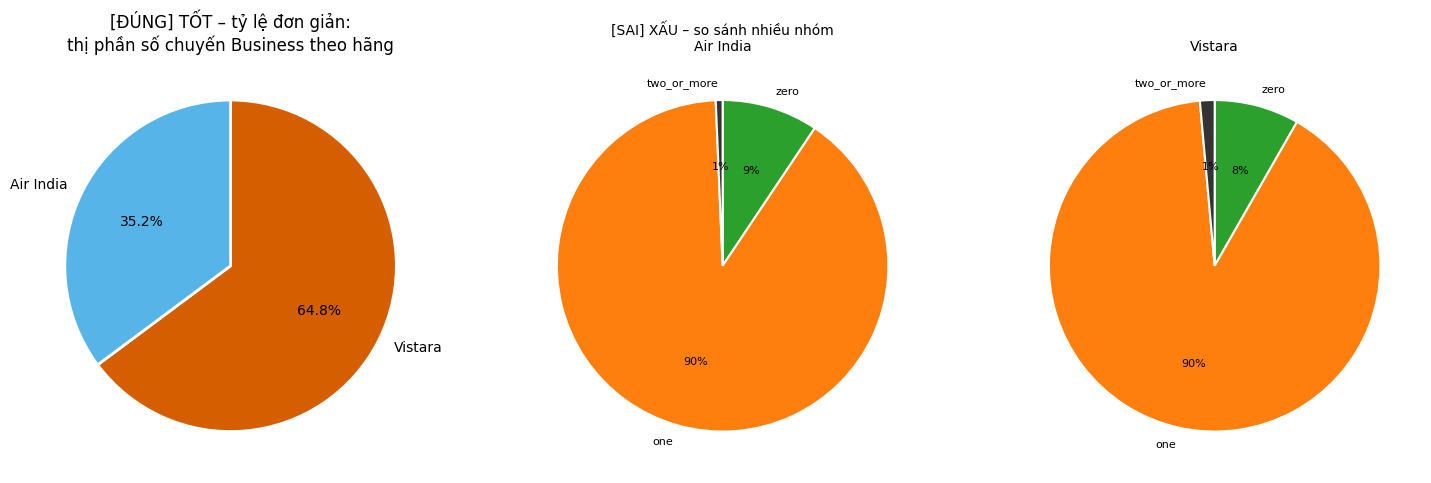

In [ ]:
share_air = pd.crosstab(bus['airline'], bus['stops'], normalize='index') * 100      # % theo hàng
pie_cols = {'zero': C_GREEN, 'one': C_ORANGE, 'two_or_more': C_DARK}

fig, axes = plt.subplots(1, 1 + len(airlines[:3]), figsize=(5 * (1 + len(airlines[:3])), 4.8))
cnt_air = bus['airline'].value_counts()
axes[0].pie(cnt_air, labels=cnt_air.index, autopct='%1.1f%%', startangle=90, counterclock=False,
            colors=[AIR_COLORS[a] for a in cnt_air.index], wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[0].set_title('[ĐÚNG] TỐT – tỷ lệ đơn giản:\nthị phần số chuyến Business theo hãng')
for j, a in enumerate(airlines[:3]):
    vals = share_air.loc[a, STOPS_ORDER]
    axes[1 + j].pie(vals, labels=STOPS_ORDER, autopct='%1.0f%%', startangle=90, counterclock=False,
                    colors=[pie_cols[s] for s in STOPS_ORDER], textprops={'fontsize': 8},
                    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
    axes[1 + j].set_title((f'[SAI] XẤU – so sánh nhiều nhóm\n' if j == 0 else '\n') + a, fontsize=10)
plt.tight_layout(); plt.show()

## 6.2 Giải pháp so sánh: Thanh cạnh nhau (Side-by-side)
Các đường cơ sở bằng phẳng giúp so sánh từng danh mục giữa các nhóm rất dễ. **Hạn chế:** không thể hiện rõ quy mô phần so với tổng thể 100%.

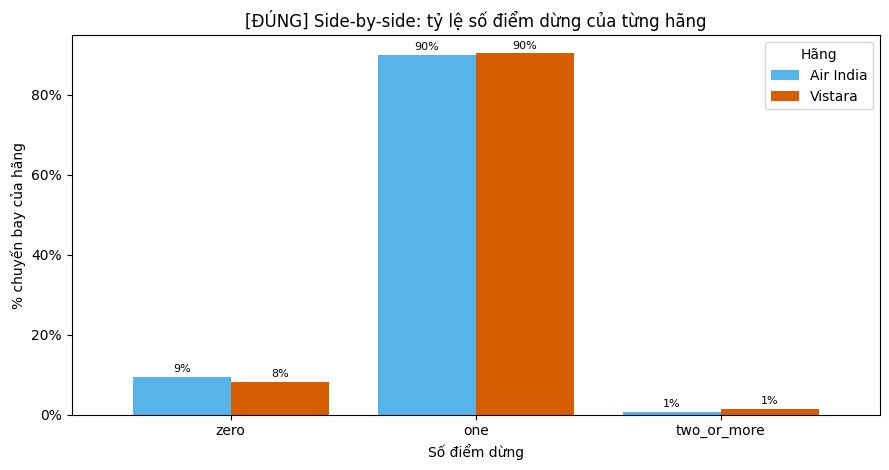

In [ ]:
sh = share_air[STOPS_ORDER]
ax = sh.T.plot.bar(figsize=(9, 4.8), width=.8, color=[AIR_COLORS[a] for a in sh.index])
ax.set_title('[ĐÚNG] Side-by-side: tỷ lệ số điểm dừng của từng hãng')
ax.set_xlabel('Số điểm dừng'); ax.set_ylabel('% chuyến bay của hãng')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(100))
plt.xticks(rotation=0)
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.0f%%', fontsize=8, padding=2)
ax.legend(title='Hãng')
plt.tight_layout(); plt.show()

## 6.3 Thanh xếp chồng – quy tắc 2 biến
Stacked 100% chỉ phát huy khi có **đúng 2 danh mục** (ở đây: 2 hãng Vistara / Air India) – thanh dưới có đường cơ sở chung và đường tham chiếu **50%** giúp thấy ngay nhóm nào chiếm đa số.

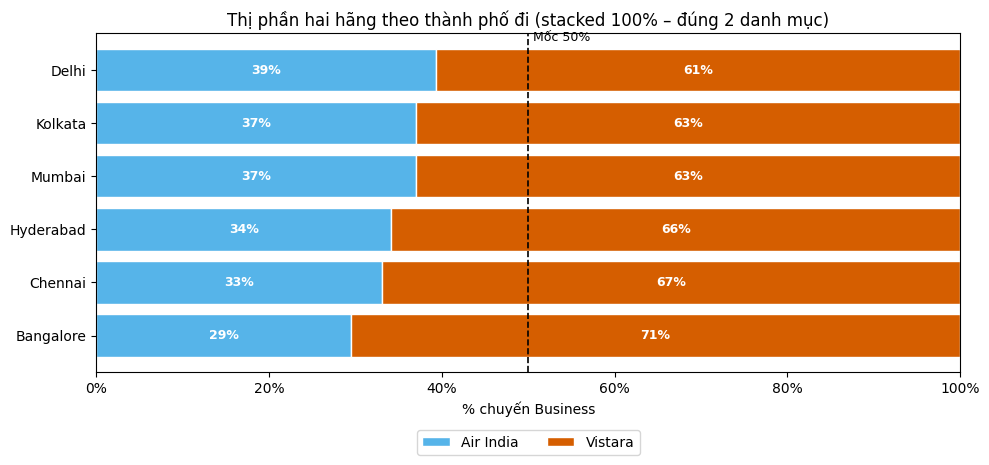

In [ ]:
cs = pd.crosstab(bus['source_city'], bus['airline'], normalize='index') * 100
cs = cs.sort_values(cs.columns[0])

fig, ax = plt.subplots(figsize=(10, 4.8))
left = np.zeros(len(cs))
for a in cs.columns:
    ax.barh(cs.index, cs[a], left=left, color=AIR_COLORS[a], label=a, edgecolor='white')
    for i, (v, l) in enumerate(zip(cs[a], left)):
        if v >= 6:
            ax.text(l + v / 2, i, f'{v:.0f}%', ha='center', va='center', color='white', fontsize=9, fontweight='bold')
    left += cs[a].values
ax.axvline(50, color='k', ls='--', lw=1.2); ax.text(50.5, len(cs) - .45, 'Mốc 50%', fontsize=9)
ax.set_xlim(0, 100); ax.xaxis.set_major_formatter(mtick.PercentFormatter(100))
ax.set_title('Thị phần hai hãng theo thành phố đi (stacked 100% – đúng 2 danh mục)')
ax.set_xlabel('% chuyến Business'); ax.set_ylabel('')
ax.legend(ncol=2, loc='upper center', bbox_to_anchor=(.5, -.15))
plt.tight_layout(); plt.show()

## 6.4 Tỷ lệ riêng biệt – Small multiples (từ 3 danh mục trở lên)
Với ≥ 3 danh mục (ở đây: 3 loại số điểm dừng), thanh ở giữa mất baseline chung ⇒ **tách thành các biểu đồ riêng**: giữ bối cảnh (xám) và làm nổi bật phần tử cần xem (xanh).

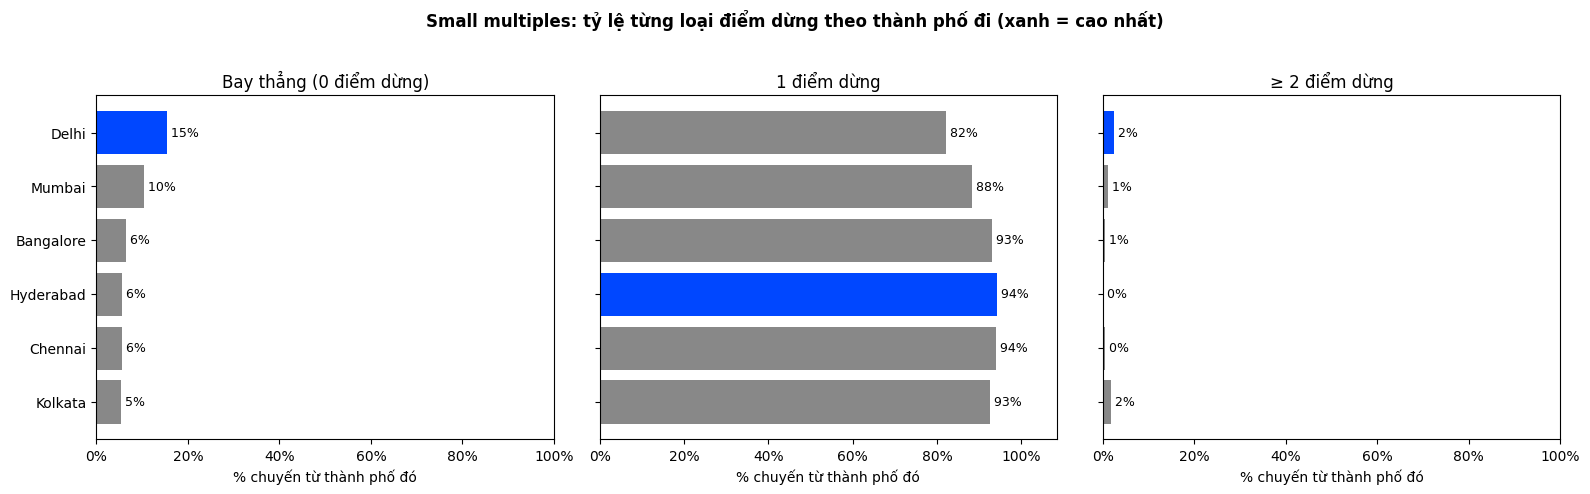

In [ ]:
C_GRAY = '#888888'

share_city = pd.crosstab(bus['source_city'], bus['stops'], normalize='index') * 100
order_c = share_city['zero'].sort_values().index.tolist()
labels_vi = {'zero': 'Bay thẳng (0 điểm dừng)', 'one': '1 điểm dừng', 'two_or_more': '≥ 2 điểm dừng'}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, c in zip(axes, STOPS_ORDER):
    vals = share_city[c].reindex(order_c)
    cols = ['#0047FF' if v == vals.max() else C_GRAY for v in vals]
    ax.barh(order_c, vals, color=cols)
    for i, v in enumerate(vals):
        ax.text(v, i, f' {v:.0f}%', va='center', fontsize=9)
    ax.set_title(labels_vi[c]); ax.set_xlim(0, max(100, vals.max() * 1.15))
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(100)); ax.set_xlabel('% chuyến từ thành phố đó')
fig.suptitle('Small multiples: tỷ lệ từng loại điểm dừng theo thành phố đi (xanh = cao nhất)', fontweight='bold', y=1.02)
plt.tight_layout(); plt.show()

**Nguyên tắc vàng:** không dùng thanh sai số cho phân phối · Ridgeline cho chuỗi thời gian · Pie cho 1 nhóm, Side-by-side cho so sánh · Stacked chỉ cho 2 biến, từ 3 biến hãy tách rời (Small multiples).

---
# 7. Tổng hợp phát hiện & kết luận
Ô dưới đây **tự tính** các con số chính từ dữ liệu Business đã làm sạch để bạn dùng khi viết nhận xét.

In [ ]:
ins = []
ins.append(f'Dữ liệu Business sau làm sạch: {len(bus):,} chuyến bay, {bus["airline"].nunique()} hãng ({", ".join(airlines)}), '
           f'{bus["source_city"].nunique()} thành phố đi, {bus["route"].nunique()} tuyến bay.')
ins.append(f'Giá Business: trung vị {bus["price"].median():,.0f} INR, trung bình {bus["price"].mean():,.0f} INR, '
           f'nhỏ nhất {bus["price"].min():,.0f}, lớn nhất {bus["price"].max():,.0f}.')

a = bus.groupby('airline', observed=True)['price'].median().sort_values()
ins.append('Giá trung vị theo hãng: ' + ', '.join(f'{k}: {v:,.0f}' for k, v in a.items()) + '.')
cnt_a = bus['airline'].value_counts(normalize=True) * 100
ins.append('Thị phần số chuyến: ' + ', '.join(f'{k}: {v:.1f}%' for k, v in cnt_a.items()) + '.')

r = bus.groupby('route', observed=True)['price'].median().sort_values()
ins.append(f'Tuyến rẻ nhất: {r.index[0]} ({r.iloc[0]:,.0f}); đắt nhất: {r.index[-1]} ({r.iloc[-1]:,.0f}).')

s = bus.groupby('stops', observed=True)['price'].median()
ins.append('Giá trung vị theo số điểm dừng: ' + ', '.join(f'{k}: {v:,.0f}' for k, v in s.items()) + '.')

t = bus.groupby('departure_time', observed=True)['price'].median().sort_values()
ins.append(f'Khung giờ rẻ nhất: {t.index[0]} ({t.iloc[0]:,.0f}); đắt nhất: {t.index[-1]} ({t.iloc[-1]:,.0f}).')

rho = stats.spearmanr(bus['duration'], bus['price'])[0]
ins.append(f'Tương quan Spearman giữa thời gian bay và giá: ρ = {rho:.2f}.')
ins.append(f'Độ lệch của giá: skew = {stats.skew(bus["price"]):.2f} (gốc) → {stats.skew(bus["price_log10"]):.2f} (sau log10); '
           f'ngoại lệ IQR: {int(bus["price_outlier"].sum()):,} dòng ({bus["price_outlier"].mean()*100:.1f}%).')

d = bus.groupby('time_group', observed=True)['price'].median()
ins.append(f'Giá trung vị theo {TG_LABEL.lower()}: ' + ', '.join(f'{k}: {v:,.0f}' for k, v in d.items()) + '.')

print('CÁC PHÁT HIỆN CHÍNH (CHỈ HẠNG BUSINESS)')
print('=' * 60)
for i, line in enumerate(ins, 1):
    print(f'{i:>2}. {line}')

CÁC PHÁT HIỆN CHÍNH (CHỈ HẠNG BUSINESS)
 1. Dữ liệu Business sau làm sạch: 93,487 chuyến bay, 2 hãng (Air India, Vistara), 6 thành phố đi, 30 tuyến bay.
 2. Giá Business: trung vị 53,164 INR, trung bình 52,540 INR, nhỏ nhất 12,000, lớn nhất 123,071.
 3. Giá trung vị theo hãng: Air India: 49,613, Vistara: 56,588.
 4. Thị phần số chuyến: Vistara: 64.8%, Air India: 35.2%.
 5. Tuyến rẻ nhất: Mumbai → Delhi (41,269); đắt nhất: Kolkata → Bangalore (60,978).
 6. Giá trung vị theo số điểm dừng: zero: 27,864, one: 54,608, two_or_more: 68,743.
 7. Khung giờ rẻ nhất: Afternoon (52,063); đắt nhất: Morning (53,743).
 8. Tương quan Spearman giữa thời gian bay và giá: ρ = 0.16.
 9. Độ lệch của giá: skew = -0.10 (gốc) → -1.21 (sau log10); ngoại lệ IQR: 3,650 dòng (3.9%).
10. Giá trung vị theo tuần khởi hành (ngày đầu tuần, dd/mm): 07/02: 59,306, 14/02: 54,608, 21/02: 53,164, 28/02: 53,152, 07/03: 53,152, 14/03: 52,726, 21/03: 52,522, 28/03: 53,152.


## 7.1 Nhận xét theo kết quả chạy trên `business.csv` (93.487 chuyến)

### A. Tổng quan & làm sạch
* Dữ liệu gồm **93.487 chuyến bay hạng Business**, 12 cột gốc (thêm cột `class`), **không có giá trị thiếu, không có dòng trùng**, chỉ có **2 hãng** (Vistara 64,8% – Air India 35,2%), **6 thành phố**, **30 tuyến bay**, ngày khởi hành trải trên **49 ngày** (11/02 → 31/03/2022), `days_left` từ 1 đến 49.
* Vấn đề của dữ liệu thô nằm ở **định dạng**, không phải ở giá trị thiếu: `price` là chuỗi có dấu phẩy (“25,612”), `time_taken` là chuỗi (“24h 45m”), `stop` chứa ký tự `\n\t` và tên điểm trung chuyển (25 giá trị khác nhau) → quy về 3 nhóm *zero / one / two_or_more*.
* Kiểm tra logic **không loại dòng nào** (giá > 0, thời gian bay hợp lý, điểm đi ≠ điểm đến). Giá nằm trong khoảng **12.000 – 123.071 INR**, trung vị **53.164**, trung bình 52.540.
* Ngoại lệ IQR: **3.650 dòng (3,9%)** – 2.373 dòng quá thấp (< ~22.400) và 1.277 dòng quá cao (> ~83.200). Giữ lại vì là giá vé thật.

### B. Mục 1.6 – Số lượng
* **Bar chart:** Mumbai có nhiều chuyến khởi hành nhất (19.858), Chennai ít nhất (12.529). Giá trung bình theo thành phố đi cao nhất ở Kolkata (≈56.600) và thấp nhất ở Delhi (≈48.700) – chênh khoảng 16%. Theo khung giờ, các cột gần như ngang nhau (≈51.000–53.700); riêng *Late_Night* chỉ có **138 chuyến** nên cột thấp hơn (≈47.000) kém tin cậy, không nên diễn giải.
* **Grouped bars:** Vistara đắt hơn Air India ở **cả 6 thành phố đi**; chênh lớn nhất ở Mumbai (59.805 so với 49.613), nhỏ nhất ở Bangalore (56.588 so với 54.684).
* **Stacked bars:** dùng cho *số chuyến* nên tổng có ý nghĩa; Vistara chiếm đa số ở mọi thành phố.
* **Dot plot (30 tuyến):** trung vị theo tuyến trải từ **41.269 (Mumbai → Delhi)** đến **60.978 (Kolkata → Bangalore)**. Ở các tuyến từ/đến Delhi, Mumbai Vistara cao hơn Air India rất rõ; ở nhóm Hyderabad–Chennai–Kolkata hai hãng gần như trùng nhau; ngược lại tuyến Chennai ↔ Bangalore thì Air India (≈60.000) đắt hơn Vistara (≈44.000).
* **Heatmap:** chênh lệch giữa các *tuyến* (≈41.000–61.000) lớn hơn nhiều so với chênh lệch giữa các *khung giờ* (trung vị chỉ 52.063–53.743) → tuyến bay là yếu tố quan trọng hơn giờ bay.

### C. Mục 1.7 – 1.8 – Phân phối
* **Histogram:** thân chính của giá nằm trong khoảng ≈40.000–65.000; do chỉ có 2.358 mức giá khác nhau trên 93.487 chuyến nên binwidth nhỏ cho hình *răng cưa*, binwidth quá lớn làm mất các đỉnh phụ ở vùng giá thấp (≈20.000–35.000).
* **KDE vs Histogram:** KDE cho đường mượt và thấy rõ phân phối **nhiều đỉnh**; cần đặt `cut=0` để đường cong không tràn ra ngoài miền giá thực tế.
* **Hai hãng:** Air India tập trung hơn (trung bình 47.131, SD 10.522) và có **đuôi trái** (P5 = 23.944); Vistara dịch sang phải và rộng hơn (trung bình 55.477, SD 13.225, P95 = 76.677, P99 = 88.916). Histogram xếp chồng khó so sánh; mật độ đè nhau và kim tự tháp thể hiện rõ sự chênh này.
* **ECDF:** trung vị Air India = **49.613**, Vistara = **56.588**; 25% vé Air India rẻ hơn 42.457 trong khi 25% vé Vistara rẻ hơn 49.207. Thời gian bay trung vị: Air India ≈14,3 giờ, Vistara ≈12,6 giờ (do 90,2% chuyến có 1 điểm dừng).
* **Log và Q-Q:** giá Business **gần đối xứng** (skew = −0,10, kurtosis dư = 0,81). Biến đổi log10 làm skew trở thành **−1,21** (lệch trái mạnh hơn, kurtosis 2,28) → với dữ liệu này **không nên log-transform** và giá cũng **không** theo log-normal hay power-law (CCDF log–log không thẳng). Q-Q của giá gốc bám đường chéo ở phần giữa, lệch ở hai đuôi (nhất là đuôi trái của Air India).

### D. Mục 1.9 – Nhiều phân phối
* **Thanh sai số mean ± SD** che mất đuôi trái, các đỉnh phụ và ngoại lệ → chỉ nên dùng box/violin/strip.
* **Strip/Box/Violin theo thành phố đi:** trung vị tăng dần từ Delhi đến Kolkata, ngoại lệ xuất hiện ở **cả hai phía**, violin cho thấy đỉnh phụ ở vùng giá thấp.
* **Theo số điểm dừng:** trung vị bay thẳng **27.864**, 1 điểm dừng **54.608**, từ 2 điểm dừng **68.743**; quy luật này giống nhau ở cả hai hãng (Air India 24.122 / 49.896 / 60.631; Vistara 28.872 / 57.017 / 71.991). Vé bay thẳng *rẻ hơn* vé có điểm dừng là điều ngược trực giác – cần kiểm chứng thêm (có thể liên quan tới cách dữ liệu ghi giá các hành trình nhiều chặng).
* **Ridgeline theo số ngày đặt trước:** từ 8–49 ngày trước giờ bay, trung vị gần như phẳng (≈52.700–53.200); nhóm **1–7 ngày** tăng lên 56.040, và riêng ngày cuối (days_left = 1) trung vị lên **65.445** → giá tăng mạnh khi sát ngày bay.

### E. Mục 1.10 – Tỷ lệ
* **Pie:** chỉ hợp để thể hiện thị phần đơn giản (Vistara 64,8% – Air India 35,2%); dùng nhiều pie để so sánh hai hãng theo số điểm dừng thì không đọc được sự khác biệt.
* **Side-by-side:** cơ cấu điểm dừng của hai hãng **gần như giống hệt nhau** (1 điểm dừng ≈90%, bay thẳng 8–9%, từ 2 điểm dừng ≈1%).
* **Stacked 100% (đúng 2 hãng):** Vistara chiếm từ **61% (Delhi)** đến **71% (Bangalore)** số chuyến, luôn vượt mốc 50%.
* **Small multiples:** tỷ lệ bay thẳng cao nhất ở Delhi (≈15%) và Mumbai (≈10%), các thành phố còn lại chỉ 5–6%; từ 2 điểm dừng gần như không đáng kể ở mọi nơi.

## 7.2 Kết luận chung
1. Dữ liệu Business **sạch về giá trị**; công việc chính là chuẩn hóa định dạng (giá, thời gian bay, số điểm dừng) và quyết định **giữ** ngoại lệ.
2. Giá Business có phân phối **gần đối xứng, nhiều đỉnh**, nên dùng histogram/density/ECDF trên **thang tuyến tính**; không cần biến đổi log khi xây mô hình.
3. Các yếu tố có ảnh hưởng rõ tới giá: **số điểm dừng**, **hãng bay** (Vistara cao hơn ≈7.000 ở trung vị), **tuyến bay** và **số ngày đặt trước** (tăng vọt trong tuần cuối). Giờ khởi hành và thời gian bay có ảnh hưởng yếu (Spearman giữa thời gian bay và giá chỉ ≈0,16).
4. Chọn biểu đồ theo đúng nguyên tắc của slide: bar/dot cho 1 biến, grouped cho so sánh nhóm, stacked chỉ cho số đếm và đúng 2 danh mục; ECDF/box/violin/ridgeline để thấy hình dạng thật thay vì thanh sai số; pie chỉ cho tỷ lệ đơn giản.